In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook
import matplotlib.cm as cm
from matplotlib.colorbar import ColorbarBase
from numpy.linalg import cholesky
from numpy.random import multivariate_normal
from scipy.optimize import curve_fit
from scipy.interpolate import UnivariateSpline

from scipy.integrate import quad, dblquad
from scipy.interpolate import interp1d
from scipy.integrate import cumulative_trapezoid
from scipy import interpolate
from scipy.special import kn  # Modified Bessel function of second kind

import os
import seaborn as sns
import pandas as pd
import importlib

#Plot param
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset']='dejavuserif'
plt.rcParams["figure.figsize"] = [15,10]
plt.rcParams["font.size"] = 10

In [2]:
#units

MeV_to_fm_m1 = 1/197.3
GeV_to_fm_m1 = 5.068
MeV_to_GeV = 1e-3
hbarc = 197.3 # MeV fm
MeV4_to_GeV_fm3 = (1e-3) * (1 / hbarc**3)

In [3]:
#temperature vectors with stepsize one
T_max = 900

T_coarse = np.linspace(120,260,260-120+1)
T_total_coarse = np.linspace(120,T_max,T_max-120+1)
T_up_coarse = np.linspace(261,T_max,T_max-261+1)

#ranges in temperature with smaller stepsize

step_down = 0.001
step_up = 0.01

T_point01_up = np.linspace(120, T_max, int((T_max - 120) / step_up) + 1)
T_point001_down = np.round(np.arange(0, 119.9 + step_down, step_down), 10)
T_total = np.concatenate((T_point001_down, T_point01_up))

T_point001_110 = T_point001_down[0:int(110/step_down)]
T_concatenate_110to120 = np.concatenate([T_point001_110, T_point01_up])

In [4]:
#switching temperature and indices

T_sw = 150 #MeV

idx_Tsw = int(len(T_point001_down) + (T_sw-120)/step_up)
idx_Tsw_up = int((T_sw-120)/step_up)

In [94]:
#temperature indices for plotting and testing

idx_30 = int(30/step_down)
idx_40 = int(40/step_down)
idx_90 = int(90/step_down)
idx_100 = int(100/step_down)
idx_110 = int(110/step_down)
idx_120 = len(T_point001_down) 
idx_130 = int(len(T_point001_down) + 10/step_up)
idx_140 = int(len(T_point001_down) + 20/step_up)
idx_150 = int(len(T_point001_down) + 30/step_up)
idx_170 = int(len(T_point001_down) + 50/step_up)

len_transition = len(T_total[0:idx_120]) - len(T_total[0:idx_110])
len_transition_unc = len(T_total[0:idx_120]) - len(T_total[0:idx_90])

## Reading in lattice data

In [6]:
data = pd.read_csv("./data/cs2_WB.dat",sep=r"\s+",header=None)

#data extracted from graph up to ~400 MeV and taken as 1/3 at 700 MeV
data_extracted = pd.read_csv("./data/cs2_data_extrap/points_extracted",sep=",",header=None)

In [7]:
lattice_cs2 = data[[0,1,2]]
extracted_cs2 = data_extracted[[0,1]]

In [8]:
lattice_cs2.columns = ['T','cs2','error']
extracted_cs2.columns = ['T_extract', 'cs2_extract']

In [9]:
lattice_cs2.to_csv("./data/data.dat", sep= ' ', index = False)
extracted_cs2.to_csv("./data/data_extracted.dat", sep= ',', index = False)

extracted_cs2_interp = interp1d(extracted_cs2['T_extract'], extracted_cs2['cs2_extract'], kind='linear') 

## GPs

In [10]:
import gp_sampler
from gp_sampler import GPSampler
importlib.reload(gp_sampler)
sampler = GPSampler(lattice_cs2, extracted_cs2, T_up_coarse, T_total_coarse)

In [11]:
#every time you tun this cell it changes all other results from below

cs2_sample = sampler.generate_sample(l=400, sigma=15) 

cs2_interp = interp1d(T_total_coarse, cs2_sample, kind='linear')

<>:72: SyntaxWarning: invalid escape sequence '\s'
<>:72: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_170504/3183605810.py:72: SyntaxWarning: invalid escape sequence '\s'
  plt.figtext(0.12, 0.9,  f'l = {l_plot}, $\sigma$ = {sigma_plot}', size=17)


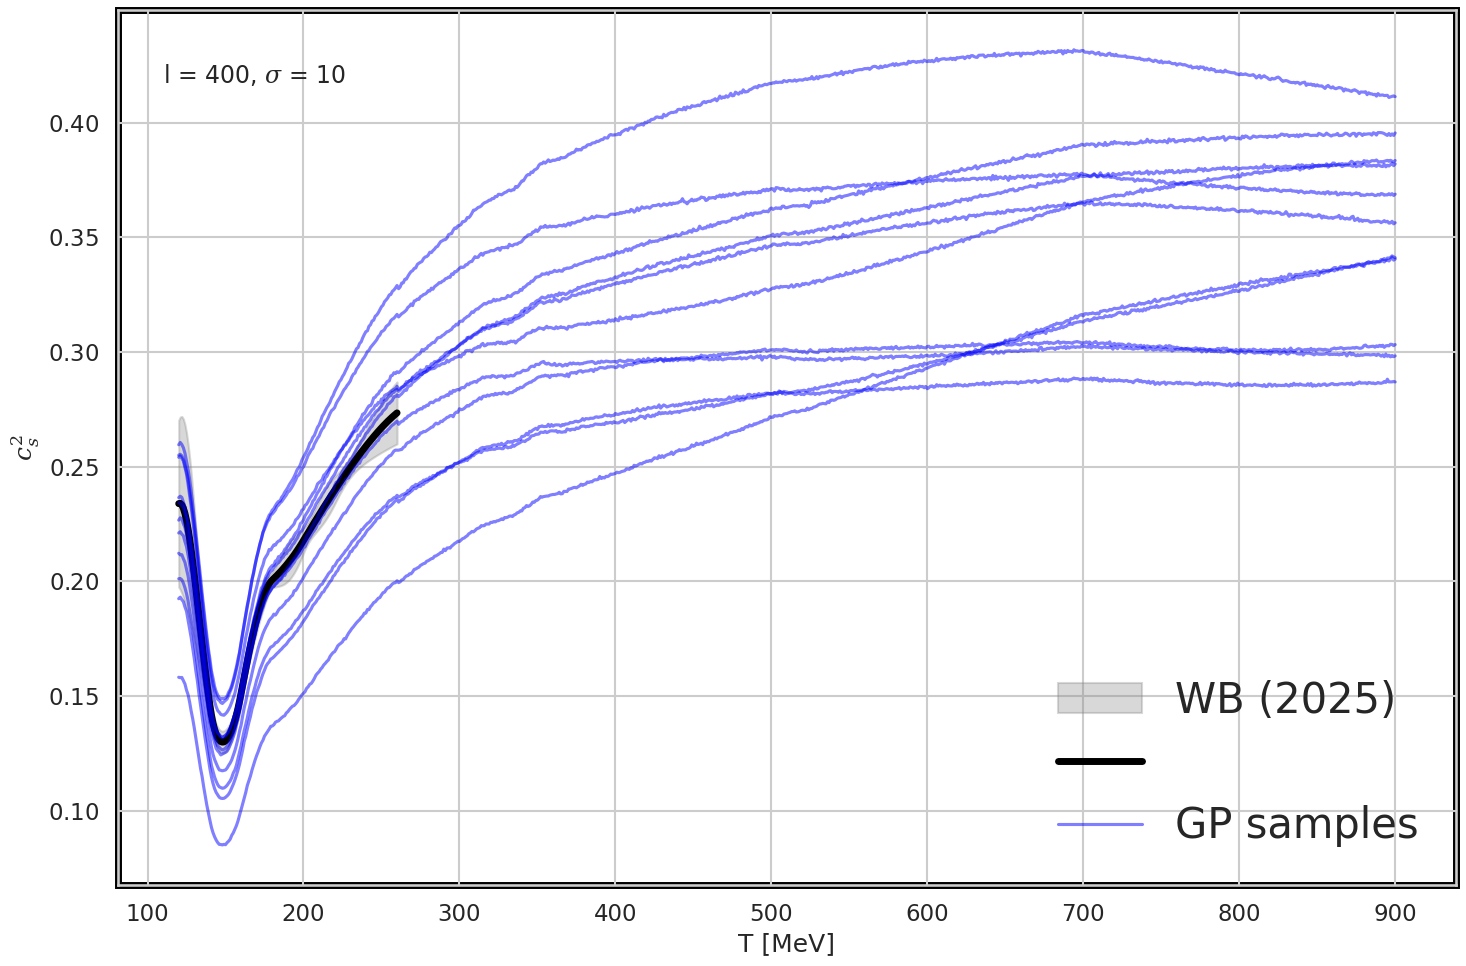

In [12]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

# Lattice error band
ax.fill_between(
    lattice_cs2['T'],
    lattice_cs2['cs2'] - lattice_cs2['error'],
    lattice_cs2['cs2'] + lattice_cs2['error'],
    alpha=0.3,
    color='gray',
    label='WB (2025)'
)

# Lattice mean line
sns.lineplot(
    data= lattice_cs2,
    x='T',
    y='cs2',
    ax=ax,
    color='black',
    linewidth=5,
    label=' '
)

for i in range(11):
    l_plot = 400
    sigma_plot = 10
    sample = sampler.generate_sample(l_plot, sigma_plot)
    ax.plot(
        T_total_coarse,
        sample,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)
plt.figtext(0.12, 0.9,  f'l = {l_plot}, $\sigma$ = {sigma_plot}', size=17)

plt.tight_layout()
plt.savefig('./images/cs2.png')
plt.show()


## HRG

In [13]:
#read particle list from file

file_path = "./data/pdg-urqmd_v3.3+.dat"

if not os.path.isfile(file_path):
    print("Unable to open file")
    exit(1)

m_bosons = []
m_fermions = []
g_b = []
g_f = []

with open(file_path, "r") as file:
    for line in file:
        
        #removes whitespace characters, including spaces, tabs, and newlines
        line = line.strip() 
        
        if not line:
            continue  # skip empty lines

        values = line.split()

        if values[1][0].isalpha():
            try:
                mass = float(values[2])
                f_or_b = int(values[5])
                g = float(values[4])
                mass_mev = mass * 1e3  #MeV

                if f_or_b == 1:
                    m_fermions.append(mass_mev)
                    g_f.append(g)
                elif f_or_b == 0:
                    m_bosons.append(mass_mev)
                    g_b.append(g)
            except ValueError:
                continue  
        elif values[1][0].isdigit():
            continue  


In [14]:

import hrg
from hrg import HRGCalculator
import numpy as np

hrg = HRGCalculator(m_fermions, g_f, m_bosons, g_b)

#saving HRG quantities to file to use later, in the range of temperatures up to 170 MeV
#only run the next line again if bigger HRG temp range needed

# hrg.save_thermo_table(T_total[:idx_170], "hrg_thermo_table.txt")

In [15]:
P_hrg_total = np.loadtxt("./data/hrg_thermo_table.txt", usecols=0, skiprows=1)
e_hrg_total = np.loadtxt("./data/hrg_thermo_table.txt", usecols=1, skiprows=1)
s_hrg_total = np.loadtxt("./data/hrg_thermo_table.txt", usecols=2, skiprows=1)

In [16]:
#T_sw can be changed above

P_sw = P_hrg_total[idx_Tsw]
e_sw = e_hrg_total[idx_Tsw]
s_sw = s_hrg_total[idx_Tsw]

In [17]:
print(P_sw*MeV4_to_GeV_fm3)
print(e_sw*MeV4_to_GeV_fm3)
print(s_sw*(1/hbarc**3))
print(s_sw)

0.05254009468115531
0.25420235570103317
2.044949666610543
15705938.0


## Thermodynamics from sample

In [18]:
def s_integrand(T, cs2_interp): 
    return 1 / (T * cs2_interp(T))

def entropy_up(s_sw, T_sw, cs2_interp, T_up):

    integrand = s_integrand(T_up, cs2_interp)
    integral = cumulative_trapezoid(integrand, T_up, initial=0)

    Int_at_Tsw = np.interp(T_sw, T_up, integral)

    #subtracts Int_at_Tsw from the integral, s(T_sw) = s_sw
    integral -= Int_at_Tsw

    s_up_vec = s_sw * np.exp(integral)
    s_interp = interp1d(T_up, s_up_vec)

    return s_interp

s_up_interp = entropy_up(s_sw, T_sw, cs2_interp, T_point01_up)

In [19]:
def P_integrand(T, s_interp):
    return s_interp(T)

def pressure_up(P_sw, T_sw, T_vec, s_interp):
    T_vec = np.asarray(T_vec)

    integrand = s_interp(T_vec)
    integral = cumulative_trapezoid(integrand, T_vec, initial=0)

    # find switch index
    i_sw = np.argmin(np.abs(T_vec - T_sw))

    # shift so that P(T_sw) = P_sw
    pressure = P_sw + integral - integral[i_sw]

    P_interp = interp1d(T_vec, pressure)

    return P_interp

P_up_interp = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp)

In [20]:
#energy upwards

def energy_up(s, P, T_vec):
    energy_vec = []
    for T in T_vec:
        energy_vec.append(s(T)*T - P(T))

    e_interp = interp1d(T_vec, energy_vec)
    return e_interp

e_up_interp = energy_up(s_up_interp, P_up_interp, T_point01_up)

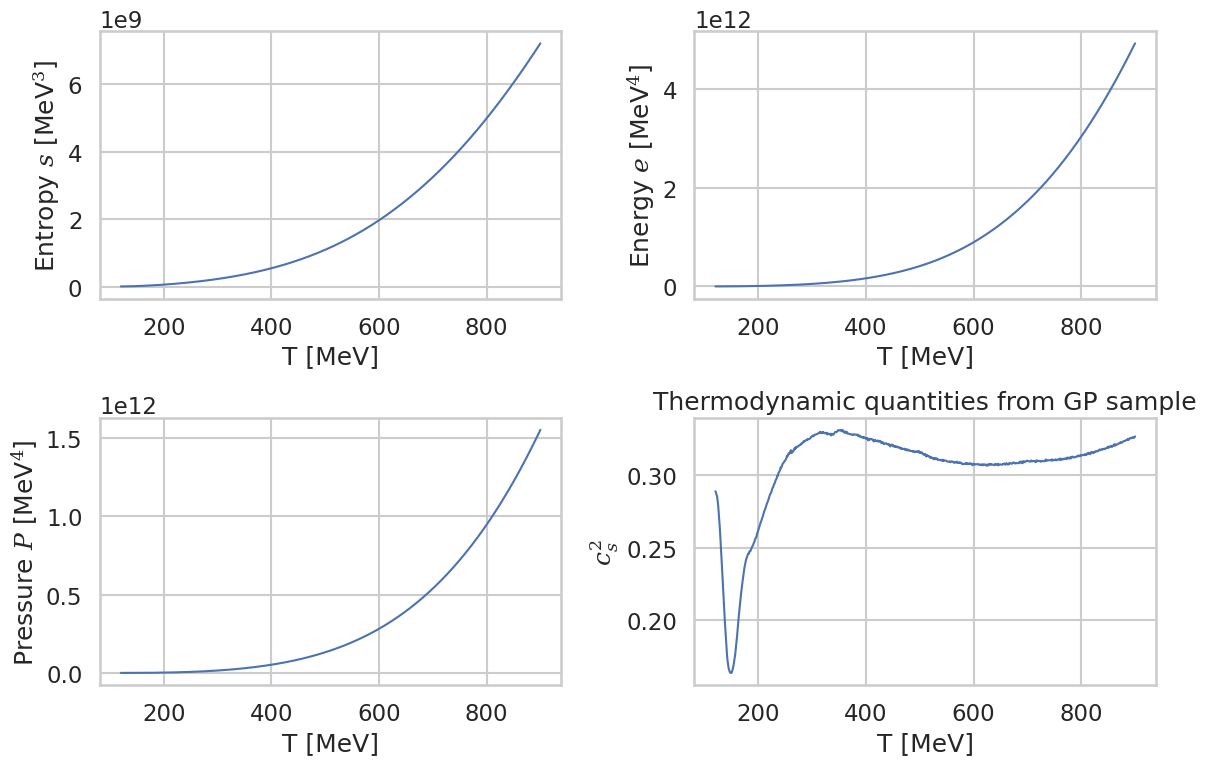

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# ---- Entropy density s ----
axes[0, 0].plot(T_point01_up, s_up_interp(T_point01_up), linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_point01_up, e_up_interp(T_point01_up), linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_point01_up, P_up_interp(T_point01_up), linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_point01_up, cs2_interp(T_point01_up), linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.title("Thermodynamic quantities from GP sample")
plt.savefig('./images/thermo_up.png')
plt.show()

## Downwards extrap

### Using a power law

In [22]:
import importlib
import extrapolation_powerlaw as extrap_pwrl

# Use power law extrapolation
thermo_pwrl = extrap_pwrl.extrapolate_powerlaw(
    T_down=T_point001_down, 
    T_up=T_point01_up, 
    T_total=T_total, 
    cs2_interp=cs2_interp, 
    s_up_interp=s_up_interp, 
    P_up_interp=P_up_interp, 
)

# Access results
P_pwrl = thermo_pwrl['pressure']
e_pwrl = thermo_pwrl['energy'] 
s_pwrl = thermo_pwrl['entropy']
cs2_pwrl = thermo_pwrl['cs2']

In [23]:
sT_pwrl = []
for i, T in enumerate(T_total):
    sT_pwrl.append(s_pwrl[i]*T)

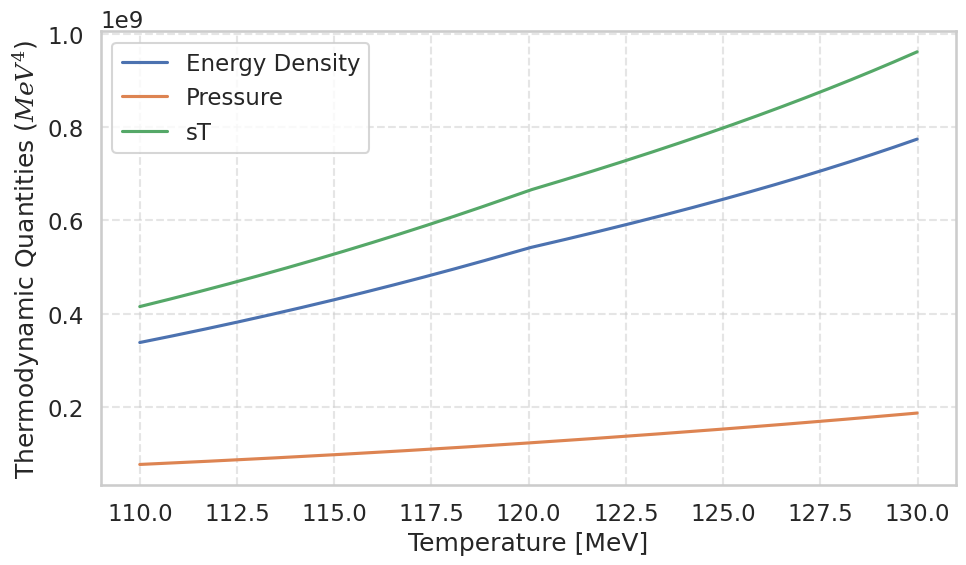

In [24]:
#plotting all thermodynamic quantities together for the range 110-130 MeV to check consistency

df = pd.DataFrame({
    'T': T_total[idx_110:idx_130],
    'Energy': e_pwrl[idx_110:idx_130],
    'Pressure': P_pwrl[idx_110:idx_130],
    'sT': sT_pwrl[idx_110:idx_130]
})

plt.figure(figsize=(10, 6))
plt.plot(df['T'], df['Energy'], label='Energy Density')
plt.plot(df['T'], df['Pressure'], label='Pressure')
plt.plot(df['T'], df['sT'], label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Thermodynamic Quantities ($MeV^4$)')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
#plt.savefig('./images/power_extrap.png')
plt.show()

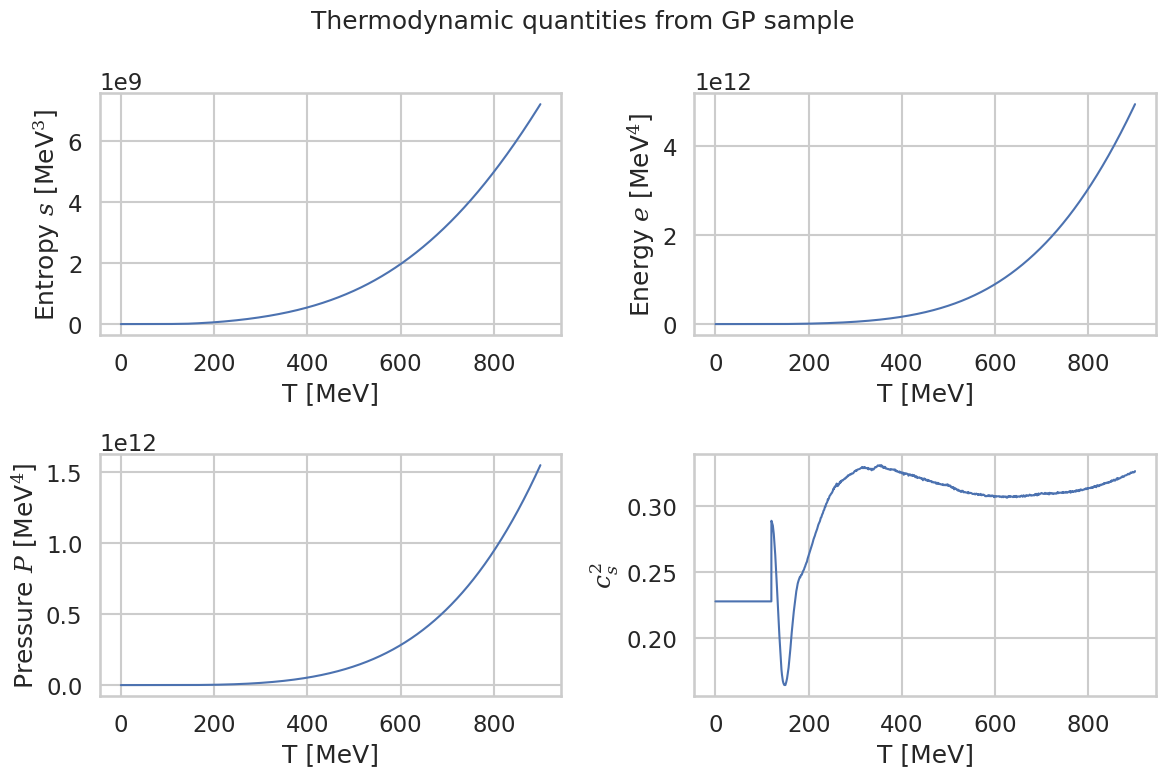

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Thermodynamic quantities from GP sample",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total, s_pwrl, linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total, e_pwrl, linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total, P_pwrl, linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total, cs2_pwrl, linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/powerLaw_extrap.png')
plt.show()

### Using HRG and performing a weighted interpolation in a transition region

In [26]:
#HRG vectors low T

P_hrg_to110 = P_hrg_total[:idx_110]
e_hrg_to110 = e_hrg_total[:idx_110]

In [27]:
s_hrg_to110 =[]
for i in range(0, len(e_hrg_to110)):
    s_hrg_to110.append(np.where(T_total[i] != 0, (e_hrg_to110[i] + P_hrg_to110[i]) / T_total[i], 0.0))

/tmp/ipykernel_170504/93237865.py:3: RuntimeWarning: invalid value encountered in scalar divide
  s_hrg_to110.append(np.where(T_total[i] != 0, (e_hrg_to110[i] + P_hrg_to110[i]) / T_total[i], 0.0))


In [28]:
import importlib
import extrapolation_weighted as extrap_w
importlib.reload(extrap_w)

# Use weighted extrapolation
thermo_w = extrap_w.extrapolate_weighted(
    P_down=P_hrg_to110,
    P_up = P_up_interp(T_point01_up),
    e_down=e_hrg_to110,
    e_up = e_up_interp(T_point01_up),
    T_up = T_point01_up,
    T_total=T_total, 
    cs2_interp=cs2_interp, 
    n_transition=len_transition,
    endpointIdx = idx_120,
)

# Access results
P_w = thermo_w['pressure']
e_w = thermo_w['energy'] 
s_w = thermo_w['entropy']
cs2_w = thermo_w['cs2']

/home/luizaperin/codes/gp/extrapolation_weighted.py:146: RuntimeWarning: invalid value encountered in divide
  s_total = np.where(T_total != 0, (P_total + e_total) / T_total, 0.0)


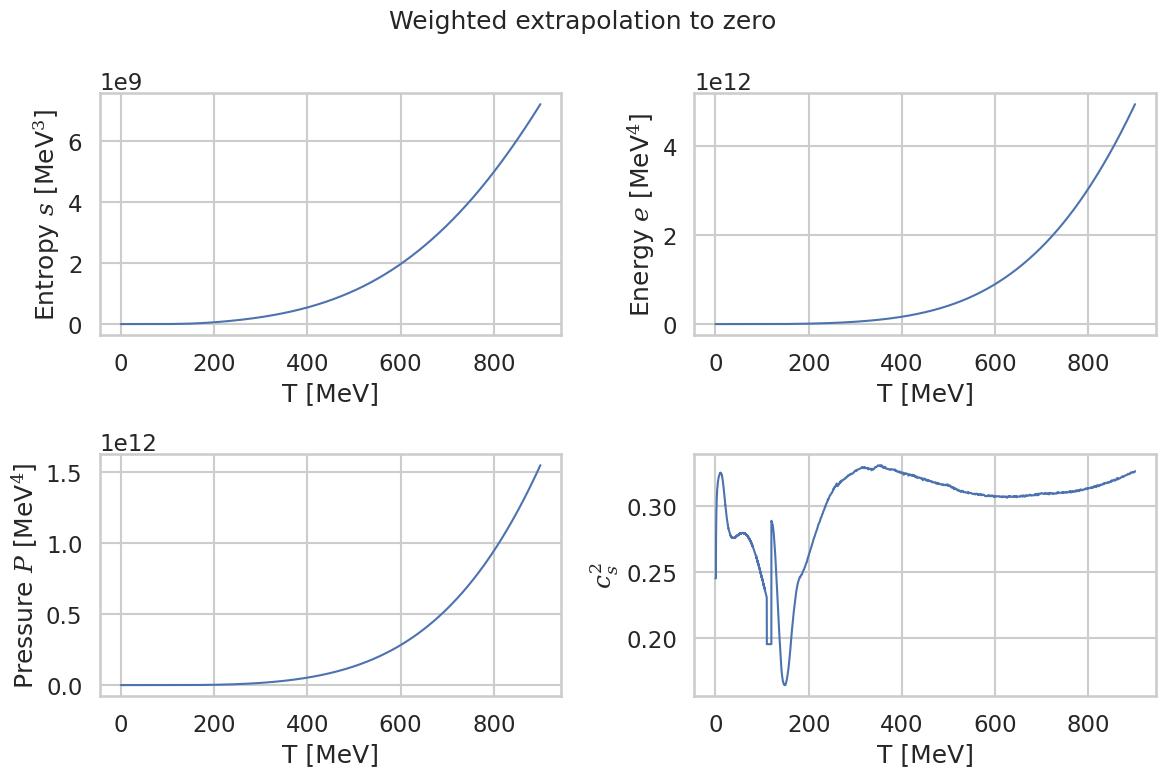

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Weighted extrapolation to zero",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total, s_w, linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total, e_w, linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total, P_w, linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total, cs2_w, linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/Weighted_extrap.png')
plt.show()

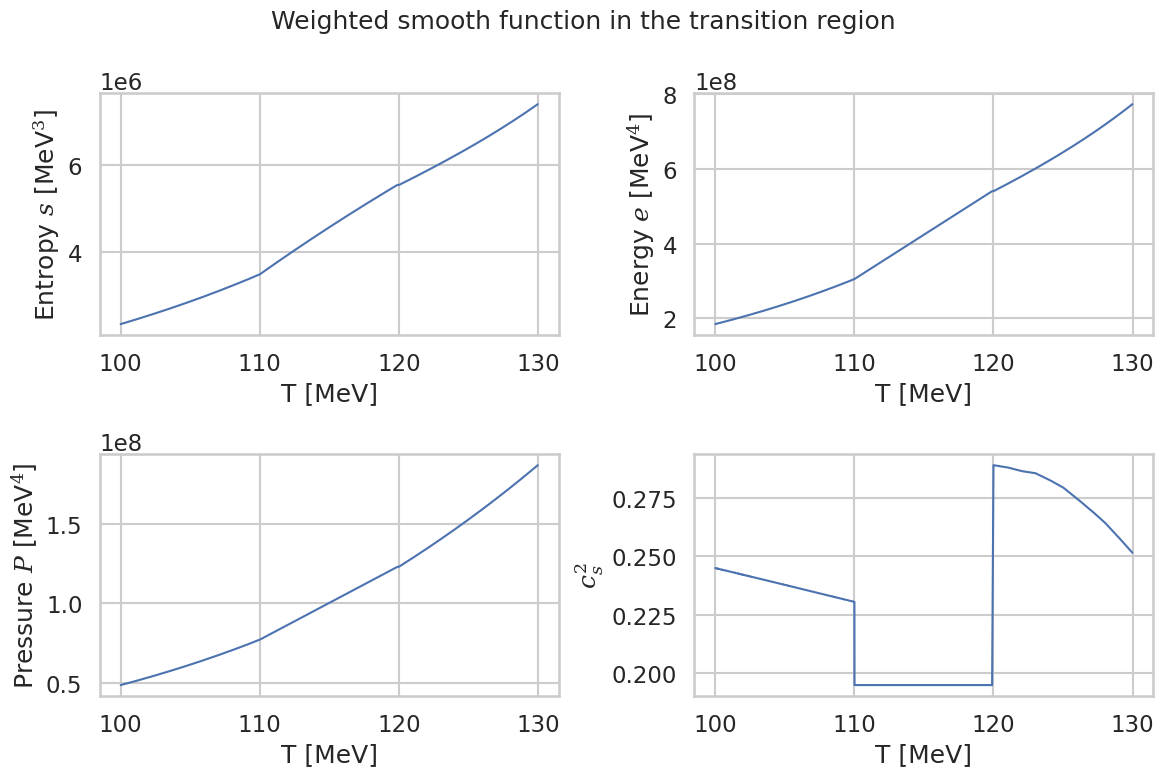

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Weighted smooth function in the transition region",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total[idx_100:idx_130], s_w[idx_100:idx_130], linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total[idx_100:idx_130], e_w[idx_100:idx_130], linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total[idx_100:idx_130], P_w[idx_100:idx_130], linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total[idx_100:idx_130], cs2_w[idx_100:idx_130], linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/Weighted_extrap_transRegion.png')
plt.show()

/tmp/ipykernel_170504/3165679486.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)


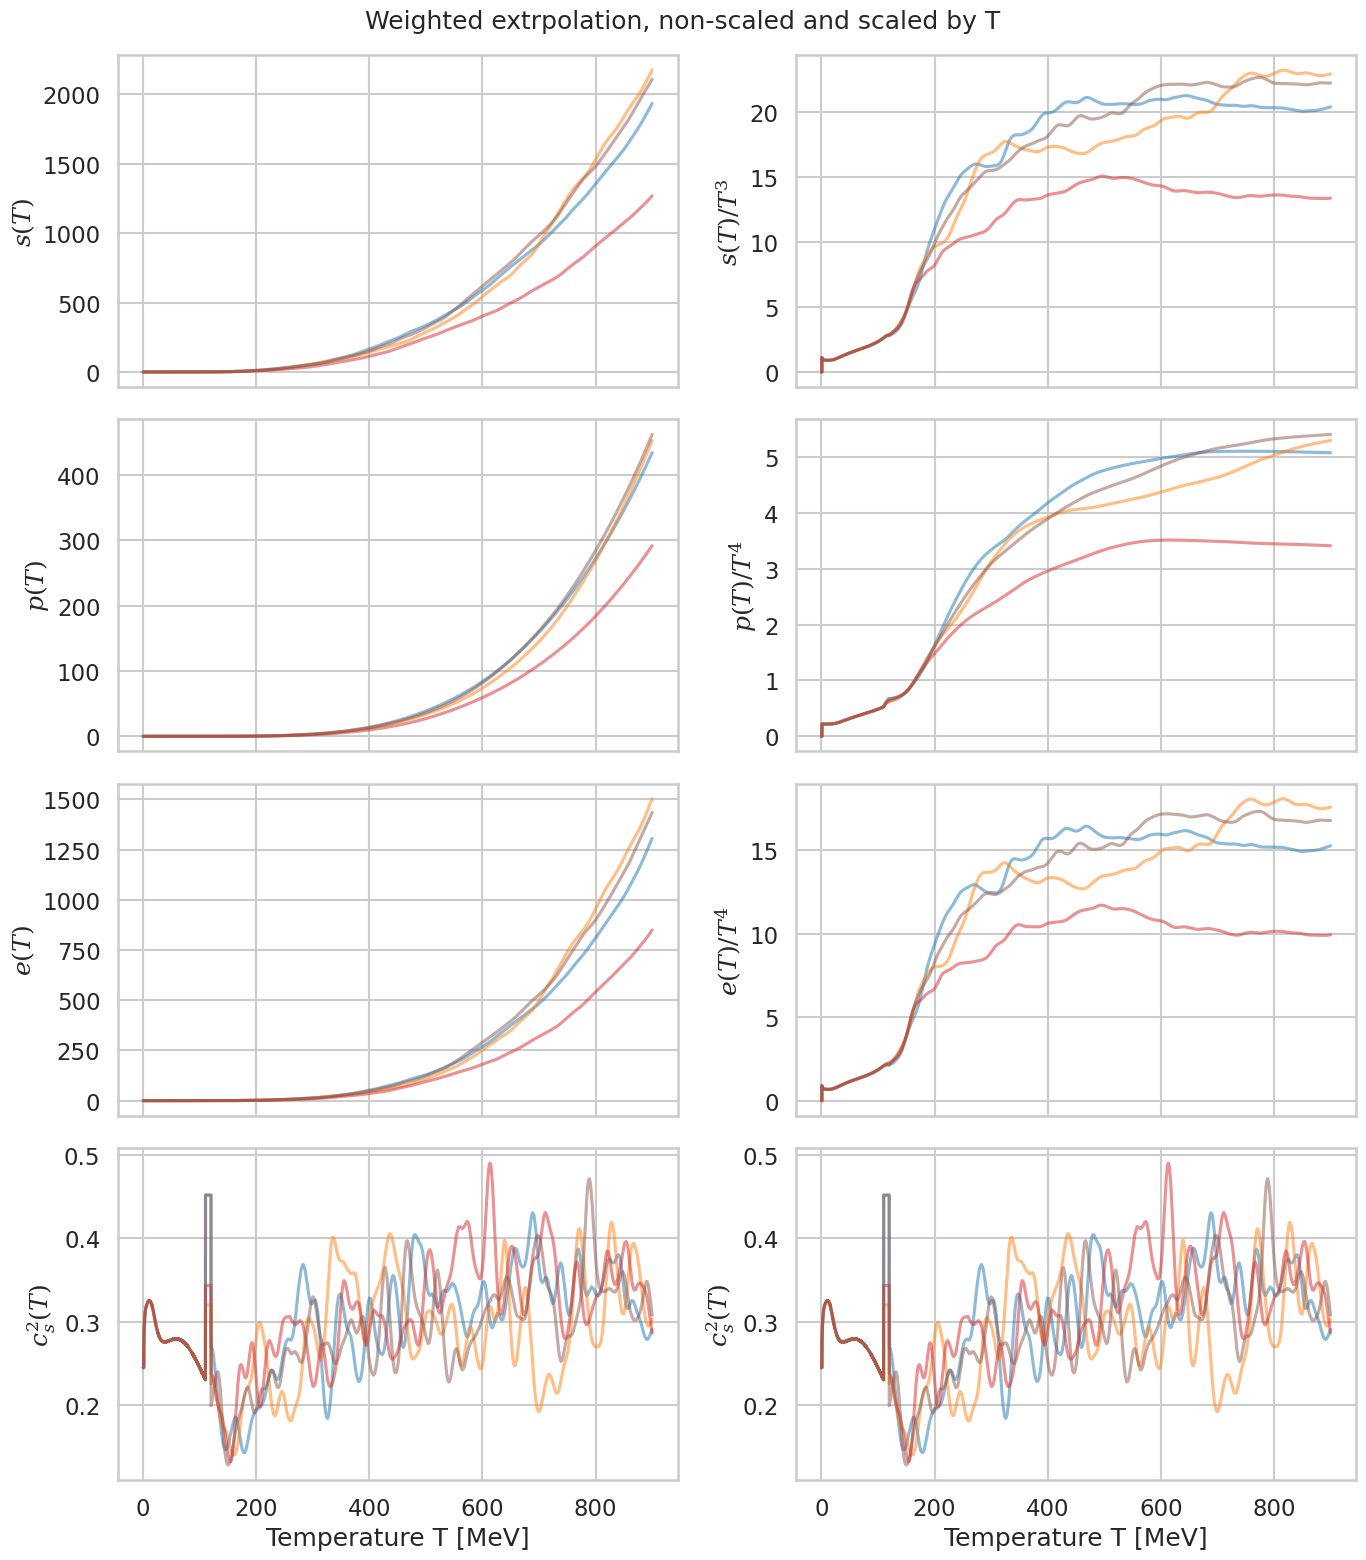

In [31]:
sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 2, figsize=(14, 16), sharex='col')
fig.suptitle("Weighted extrpolation, non-scaled and scaled by T", fontsize=18)
cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

n = 4

cs2_array_plotting = []

T_divide = T_total[500:]

for i in range(n):
     while True:
        cs2_plot = sampler.generate_sample(l=10, sigma=15)
        cs2_plotInterp = interp1d(T_total_coarse, cs2_plot, kind='linear')
        
        s_up_interp_plot = entropy_up(s_sw, T_sw, cs2_plotInterp, T_point01_up)
        P_up_interp_plot = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp_plot)
        e_up_interp_plot = energy_up(s_up_interp_plot, P_up_interp_plot, T_point01_up)
        
        thermo_w_plot = extrap_w.extrapolate_weighted(
          P_down=P_hrg_to110,
          P_up = P_up_interp_plot(T_point01_up),
          e_down=e_hrg_to110,
          e_up = e_up_interp_plot(T_point01_up),
          T_up = T_point01_up,
          T_total=T_total, 
          cs2_interp=cs2_plotInterp, 
          n_transition=len_transition,
          endpointIdx = idx_120
          )    

        P_w_plot = thermo_w_plot['pressure']
        e_w_plot = thermo_w_plot['energy'] 
        s_w_plot = thermo_w_plot['entropy']
        cs2_w_plot = thermo_w_plot['cs2']
        adjusted_transition_P = thermo_w_plot['adjusted_transition_P']
        adjusted_transition_e = thermo_w_plot['adjusted_transition_e']

        cs2_region = thermo_w_plot['cs2'][idx_110:idx_120]
        if np.any((cs2_region < 0) | (cs2_region > 1.0001)):
           continue
        if adjusted_transition_P != adjusted_transition_e:
           print("Rejected sample: transition width adjusted")
           continue

        cs2_array_plotting.append(cs2_plotInterp)
        
        color = colors[i] 
        axs[0,0].plot(T_total, s_w_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
        axs[1,0].plot(T_total, P_w_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
        axs[2,0].plot(T_total, e_w_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
        axs[3,0].plot(T_total, cs2_w_plot, color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

        axs[0,1].plot(T_divide, s_w_plot[500:] / T_divide**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
        axs[1,1].plot(T_divide, P_w_plot[500:] / T_divide**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
        axs[2,1].plot(T_divide, e_w_plot[500:] / T_divide**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
        axs[3,1].plot(T_divide, cs2_w_plot[500:], color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

        break  # exit while loop if sample is accepted
     
 # Labels and layout
labels_left = [
    r"$s(T)$",
    r"$p(T)$",
    r"$e(T)$",
    r"$c_s^2(T)$"
]

labels_right = [
    r"$s(T)/T^3$",
    r"$p(T)/T^4$",
    r"$e(T)/T^4$",
    r"$c_s^2(T)$"
]

for i in range(4):
    axs[i, 0].set_ylabel(labels_left[i])
    axs[i, 1].set_ylabel(labels_right[i])

axs[3, 0].set_xlabel("Temperature T [MeV]")
axs[3, 1].set_xlabel("Temperature T [MeV]")

for ax_row in axs:
    for ax in ax_row:
        ax.grid(True)

plt.tight_layout()
plt.savefig("./images/eos_weighted_combined.png", dpi=300)
plt.show()

### Taking it as a HRG up to switching temperature

In [32]:
P_hrgtoTsw = P_hrg_total[:idx_Tsw]
e_hrgtoTsw = e_hrg_total[:idx_Tsw]
s_hrgtoTsw = s_hrg_total[:idx_Tsw]

In [33]:
import importlib
import extrapolation_hrg as extrap_hrg
importlib.reload(extrap_hrg)

# Use weighted extrapolation
thermo_hrg = extrap_hrg.extrapolate_hrg(
    P_down=P_hrgtoTsw,
    P_up = P_up_interp,
    e_down=e_hrgtoTsw,
    e_up=e_up_interp,
    s_down=s_hrgtoTsw,
    s_up=s_up_interp,
    T_total = T_total,
    cs2_interp=cs2_interp,
    idx_Tsw = idx_Tsw,
)

# Access results
P_hrg = thermo_hrg['pressure']
e_hrg = thermo_hrg['energy'] 
s_hrg = thermo_hrg['entropy']
cs2_hrg = thermo_hrg['cs2']

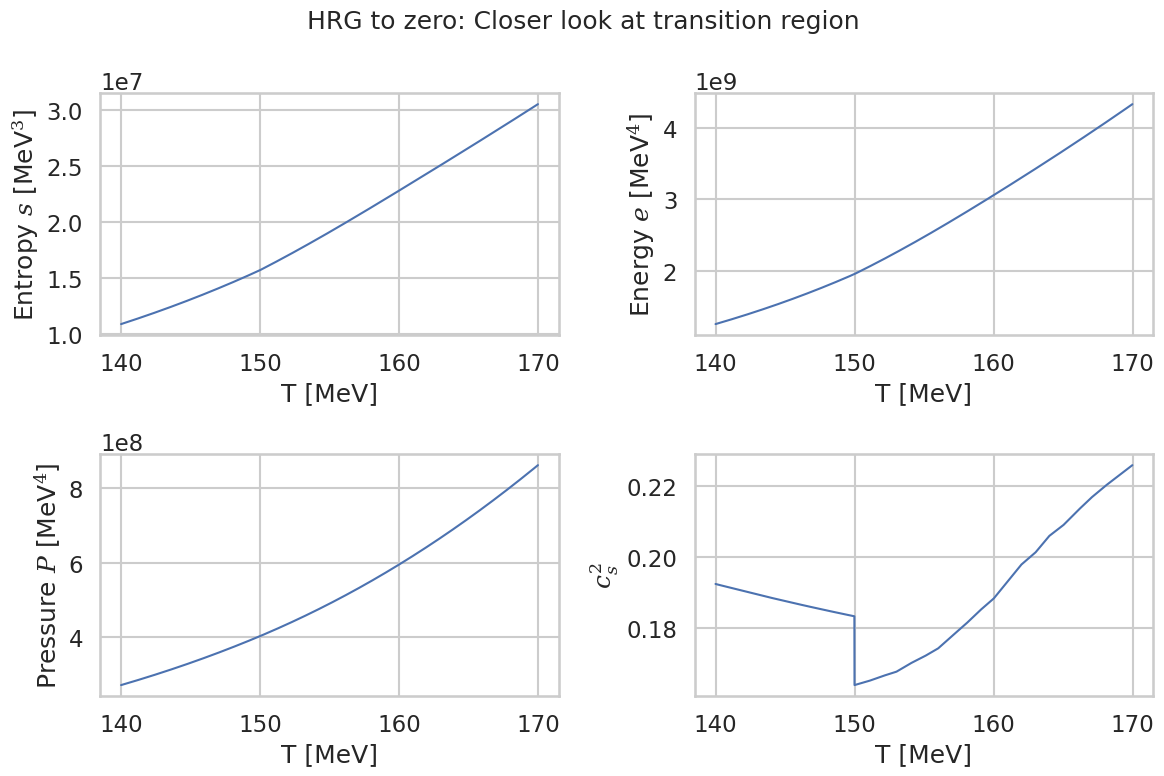

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("HRG to zero: Closer look at transition region",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total[idx_140:idx_170], s_hrg[idx_140:idx_170], linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total[idx_140:idx_170], e_hrg[idx_140:idx_170], linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total[idx_140:idx_170], P_hrg[idx_140:idx_170], linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total[idx_140:idx_170], cs2_hrg[idx_140:idx_170], linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/HRG_extrap_Closer.png')
plt.show()

/tmp/ipykernel_170504/3249914686.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)


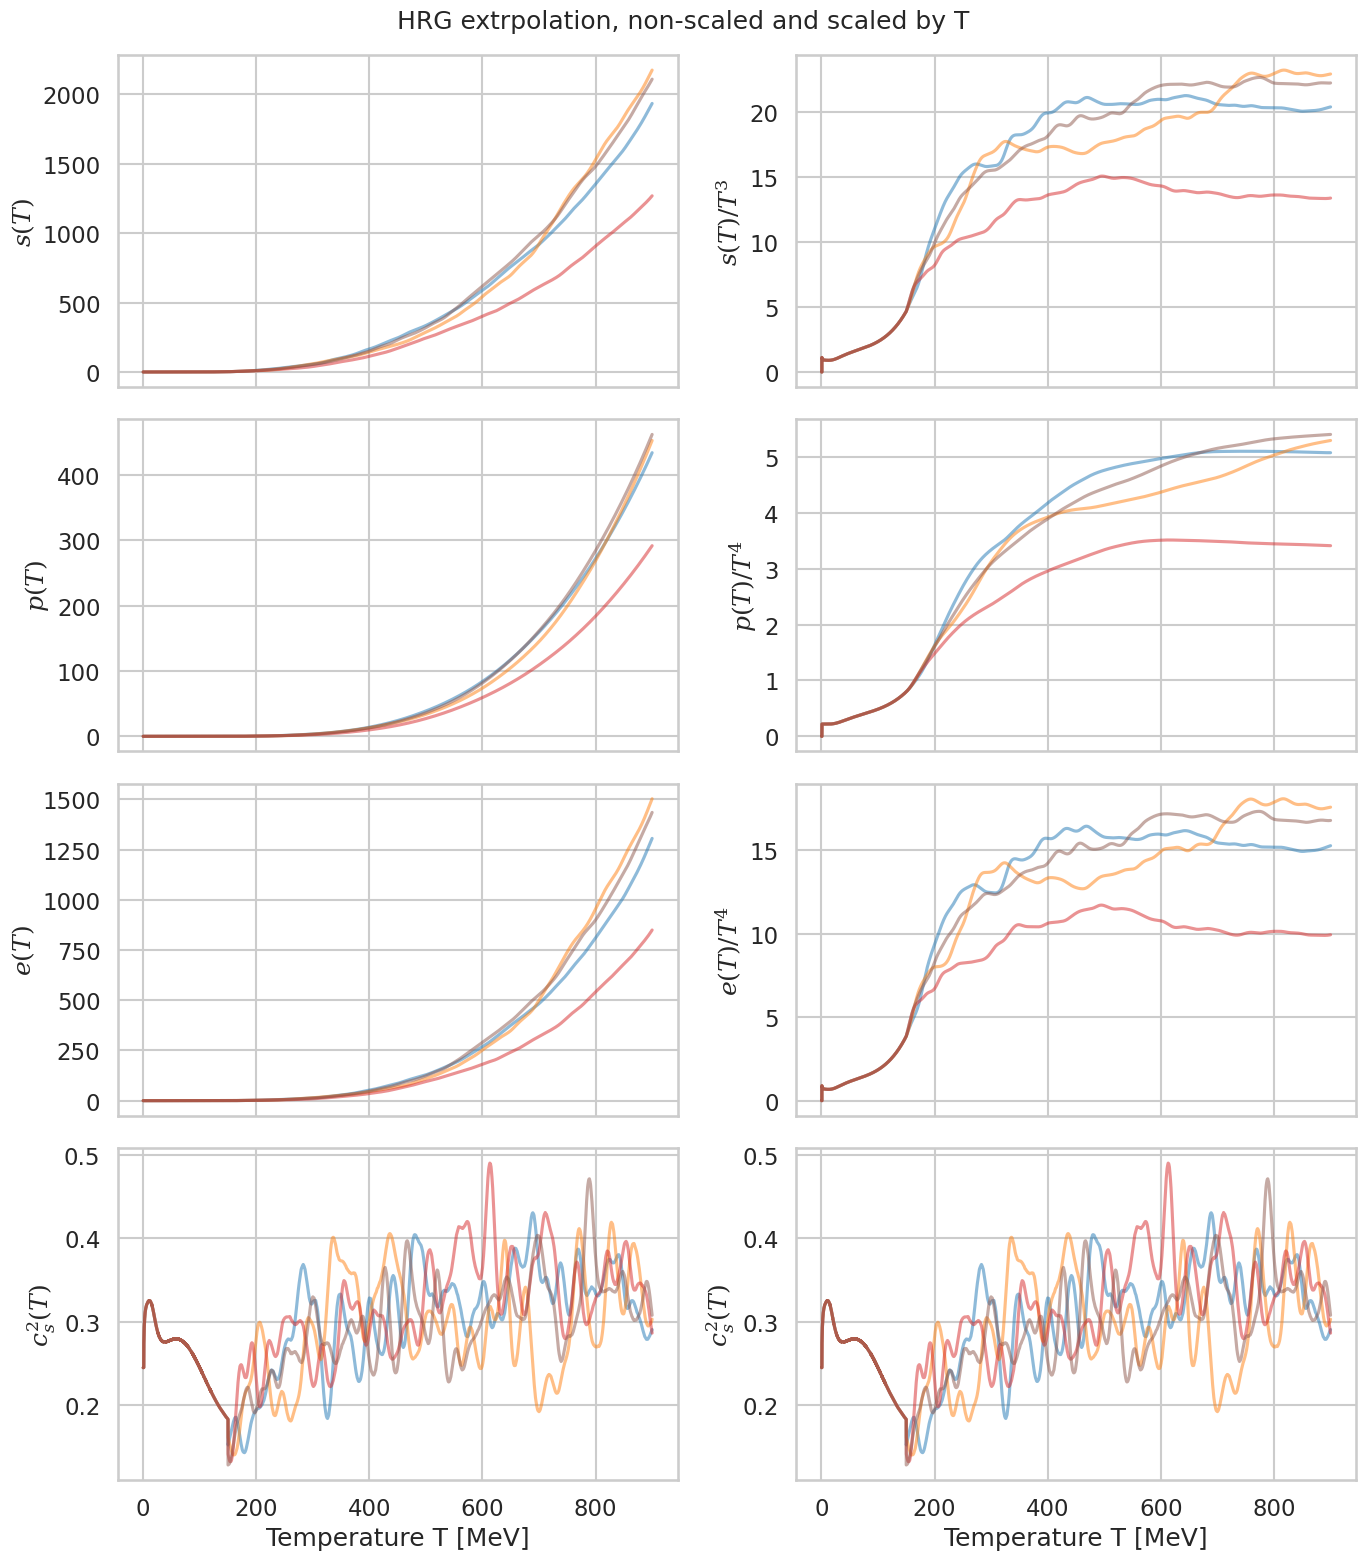

In [35]:
sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 2, figsize=(14, 16), sharex='col')
fig.suptitle("HRG extrpolation, non-scaled and scaled by T", fontsize=18)
cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

for i in range(n):
     while True:

        s_up_interp_plot = entropy_up(s_sw, T_sw, cs2_array_plotting[i], T_point01_up)
        P_up_interp_plot = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp_plot)
        e_up_interp_plot = energy_up(s_up_interp_plot, P_up_interp_plot, T_point01_up)
        
        thermo_hrg_plot = extrap_hrg.extrapolate_hrg(
            P_down=P_hrgtoTsw,
            P_up = P_up_interp_plot,
            e_down=e_hrgtoTsw,
            e_up=e_up_interp_plot,
            s_down=s_hrgtoTsw,
            s_up=s_up_interp_plot,
            T_total = T_total,
            cs2_interp=cs2_array_plotting[i],
            idx_Tsw = idx_Tsw,
        )   

        P_hrg_plot = thermo_hrg_plot['pressure']
        e_hrg_plot = thermo_hrg_plot['energy'] 
        s_hrg_plot = thermo_hrg_plot['entropy']
        cs2_hrg_plot = thermo_hrg_plot['cs2']
        
        color = colors[i] 
        axs[0,0].plot(T_total, s_hrg_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
        axs[1,0].plot(T_total, P_hrg_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
        axs[2,0].plot(T_total, e_hrg_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
        axs[3,0].plot(T_total, cs2_hrg_plot, color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

        axs[0,1].plot(T_divide, s_hrg_plot[500:] / T_divide**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
        axs[1,1].plot(T_divide, P_hrg_plot[500:] / T_divide**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
        axs[2,1].plot(T_divide, e_hrg_plot[500:] / T_divide**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
        axs[3,1].plot(T_divide, cs2_hrg_plot[500:], color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

        break  # exit while loop if sample is accepted
     
 # Labels and layout
labels_left = [
    r"$s(T)$",
    r"$p(T)$",
    r"$e(T)$",
    r"$c_s^2(T)$"
]

labels_right = [
    r"$s(T)/T^3$",
    r"$p(T)/T^4$",
    r"$e(T)/T^4$",
    r"$c_s^2(T)$"
]

for i in range(4):
    axs[i, 0].set_ylabel(labels_left[i])
    axs[i, 1].set_ylabel(labels_right[i])

axs[3, 0].set_xlabel("Temperature T [MeV]")
axs[3, 1].set_xlabel("Temperature T [MeV]")

for ax_row in axs:
    for ax in ax_row:
        ax.grid(True)

plt.tight_layout()
plt.savefig("./images/eos_hrg_combined.png", dpi=300)
plt.show()

## Saving to file (constrained gp)

In [36]:
# for constrained GP 

def save_constrained_gp_files(sample_idx, l, sigma):
    while True:
        cs2_sample_file = sampler.generate_sample(l=10, sigma=15)
        cs2_interp_file = interp1d(T_total_coarse, cs2_sample_file) 

        s_up_file = entropy_up(s_sw, T_sw, cs2_interp_file, T_point01_up)
        P_up_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_file)
        e_up_file = energy_up(s_up_file, P_up_file, T_point01_up)

        #pwr extrap 
        thermo_pwrl_file = extrap_pwrl.extrapolate_powerlaw(
          T_down=T_point001_down, 
          T_up=T_point01_up, 
          T_total=T_total, 
          cs2_interp=cs2_interp_file, 
          s_up_interp=s_up_file, 
          P_up_interp=P_up_file, 
        )

        P_pwrl_file = thermo_pwrl_file['pressure']
        e_pwrl_file = thermo_pwrl_file['energy'] 
        s_pwrl_file = thermo_pwrl_file['entropy']
        cs2_pwrl_file = thermo_pwrl_file['cs2']

        #weighted extrap 
        thermo_w_file = extrap_w.extrapolate_weighted(
          P_down=P_hrg_to110,
          P_up = P_up_file(T_point01_up),
          e_down=e_hrg_to110,
          e_up = e_up_file(T_point01_up),
          T_up = T_point01_up,
          T_total=T_total, 
          cs2_interp=cs2_interp_file, 
          n_transition=len_transition,
          endpointIdx = idx_120
        )    

        P_w_file = thermo_w_file['pressure']
        e_w_file = thermo_w_file['energy'] 
        s_w_file = thermo_w_file['entropy']
        cs2_w_file = thermo_w_file['cs2']
        adjusted_transition_P = thermo_w_file["adjusted_transition_P"]
        adjusted_transition_e = thermo_w_file["adjusted_transition_e"]

        cs2_region = thermo_w_file['cs2'][idx_110:idx_120]

        if adjusted_transition_P != adjusted_transition_e:
           print("Rejected sample: transition width adjusted")
           continue

        if np.any((cs2_region < 0) | (cs2_region > 1.0001)):
           print("Rejected sample: cs2 out of bounds in transition region")
           continue

        #hrg to 150 vectors
        thermo_hrg_file = extrap_hrg.extrapolate_hrg(
          P_down=P_hrgtoTsw,
          P_up = P_up_file,
          e_down=e_hrgtoTsw,
          e_up=e_up_file,
          s_down=s_hrgtoTsw,
          s_up=s_up_file,
          T_total = T_total,
          cs2_interp=cs2_interp_file,
          idx_Tsw = idx_Tsw,
        )   

        P_hrg_file = thermo_hrg_file['pressure']
        e_hrg_file = thermo_hrg_file['energy'] 
        s_hrg_file = thermo_hrg_file['entropy']
        cs2_hrg_file = thermo_hrg_file['cs2']

        with open(f"./eosDataFiles/constrained/l{l}_s{sigma}/eos_pwr_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(e_pwrl_file)}\n")
            for e, T, p, cs2, s in zip(e_pwrl_file, T_total, P_pwrl_file, cs2_pwrl_file, s_pwrl_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./eosDataFiles/constrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(e_w_file)}\n")
            for e, T, p, cs2, s in zip(e_w_file, T_total, P_w_file, cs2_w_file, s_w_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./eosDataFiles/constrained/l{l}_s{sigma}/eos_hrg_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(e_hrg_file)}\n")
            for e, T, p, cs2, s in zip(e_hrg_file, T_total, P_hrg_file, cs2_hrg_file, s_hrg_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n") 
    
        break

In [37]:
for i in range(0, 10):
    save_constrained_gp_files(sample_idx=i, l=400, sigma=15) 

n_transition adjusted to 14040
Rejected sample: transition width adjusted
n_transition adjusted to 22677
Rejected sample: transition width adjusted
n_transition adjusted to 12162
Rejected sample: transition width adjusted
Rejected sample: cs2 out of bounds in transition region
n_transition adjusted to 18123
Rejected sample: transition width adjusted
Rejected sample: cs2 out of bounds in transition region
n_transition adjusted to 13211
Rejected sample: transition width adjusted
Rejected sample: cs2 out of bounds in transition region
n_transition adjusted to 10695
Rejected sample: transition width adjusted
n_transition adjusted to 13830
Rejected sample: transition width adjusted
n_transition adjusted to 10255
Rejected sample: transition width adjusted
n_transition adjusted to 24910
Rejected sample: transition width adjusted
n_transition adjusted to 20415
Rejected sample: transition width adjusted
Rejected sample: cs2 out of bounds in transition region


## Unconstrained GP

In [38]:
cs2_unconstrained = sampler.generate_sample_unconstrained(l=10, sigma=15, cte_mean=0.3) 

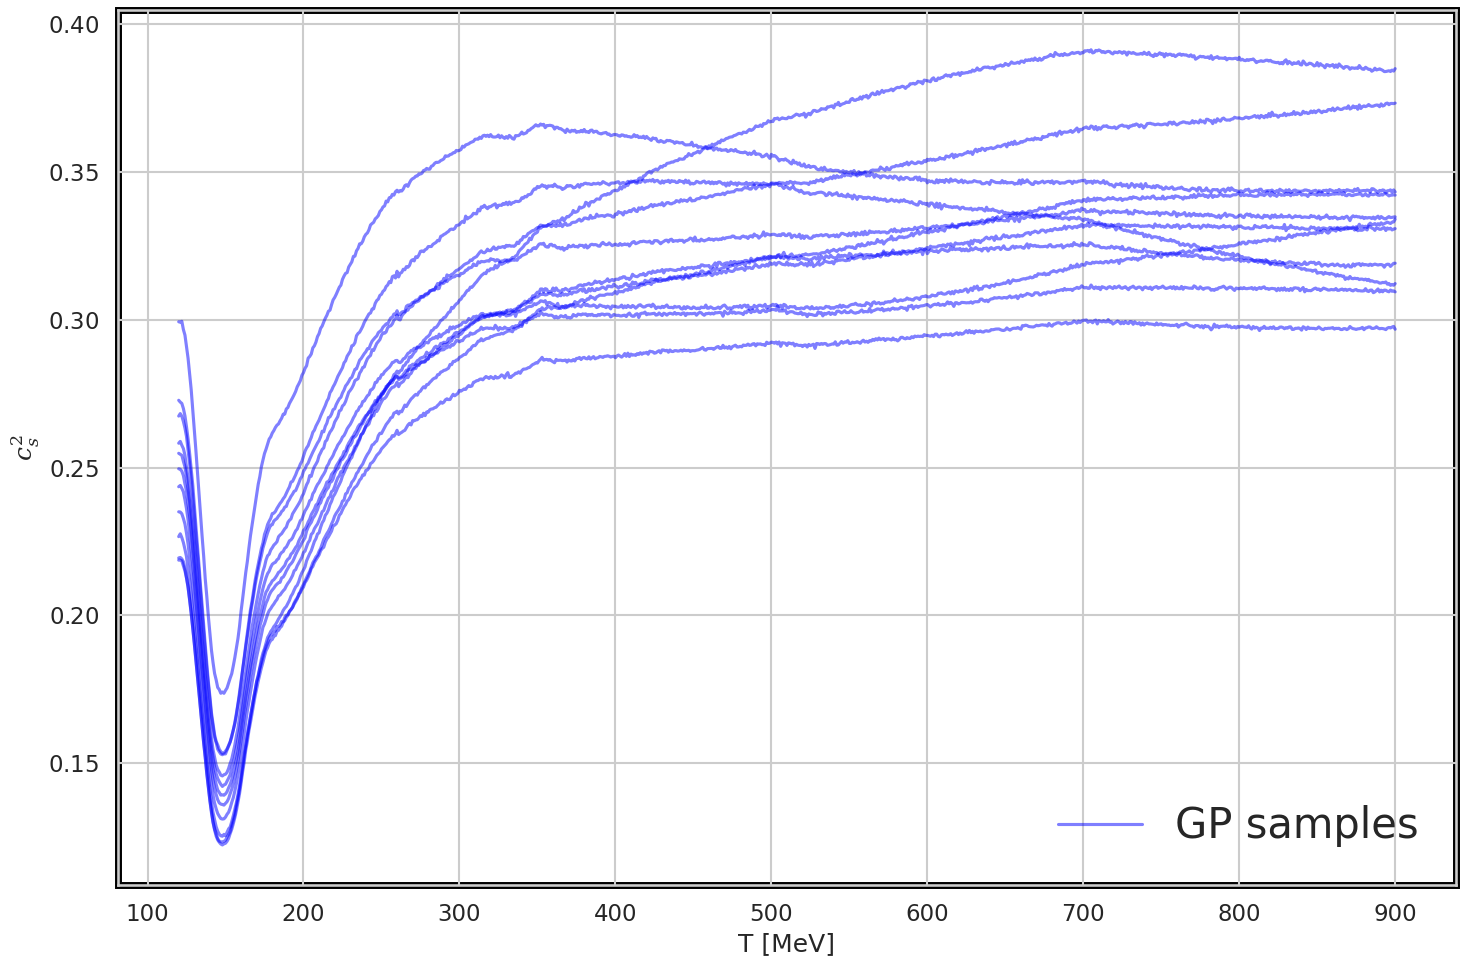

In [39]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

for i in range(11):
    l_plot = 400
    sigma_plot = 10
    sample_unc = sampler.generate_sample(l_plot, sigma_plot)
    
    ax.plot(
        T_total_coarse,
        sample_unc,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2_unc.png')
plt.show()

In [40]:
#running this changes results below

cs2_sample_unc = sampler.generate_sample_unconstrained(l=10, sigma=15, cte_mean=0.3) 
cs2_interp_unc = interp1d(T_total_coarse, cs2_sample_unc, kind='linear')


In [41]:
#entropy, pressure and energy upwards
s_up_interp_unc = entropy_up(s_sw, T_sw, cs2_interp_unc, T_point01_up)

P_up_interp_unc = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp_unc)

e_up_interp_unc = energy_up(s_up_interp_unc, P_up_interp_unc, T_point01_up)

### Weighted interpolation

In [85]:
# Use weighted extrapolation
thermo_w_unc = extrap_w.extrapolate_weighted(
    P_down=P_hrg_to110[:idx_90],
    P_up = P_up_interp_unc(T_point01_up),
    e_down=e_hrg_to110[:idx_90],
    e_up = e_up_interp_unc(T_point01_up),
    T_total=T_total, 
    cs2_interp=cs2_interp_unc, 
    n_transition=len_transition_unc,
    T_up = T_point01_up,
    endpointIdx = idx_120,
)

# Access results
P_w_unc = thermo_w_unc['pressure']
e_w_unc = thermo_w_unc['energy'] 
s_w_unc = thermo_w_unc['entropy']
cs2_w_unc = thermo_w_unc['cs2']

/home/luizaperin/codes/gp/extrapolation_weighted.py:146: RuntimeWarning: invalid value encountered in divide
  s_total = np.where(T_total != 0, (P_total + e_total) / T_total, 0.0)


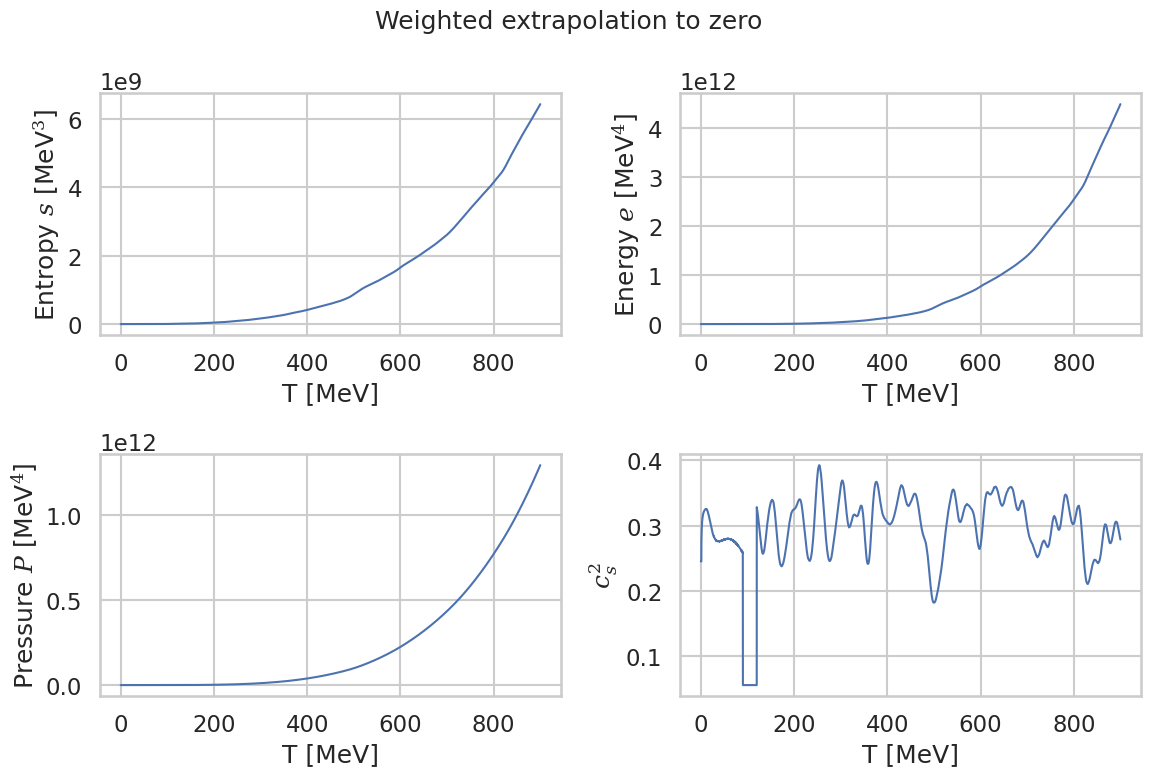

In [86]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Weighted extrapolation to zero",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total, s_w_unc, linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total, e_w_unc, linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total, P_w_unc, linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total, cs2_w_unc, linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/Weighted_extrap_unc.png')
plt.show()

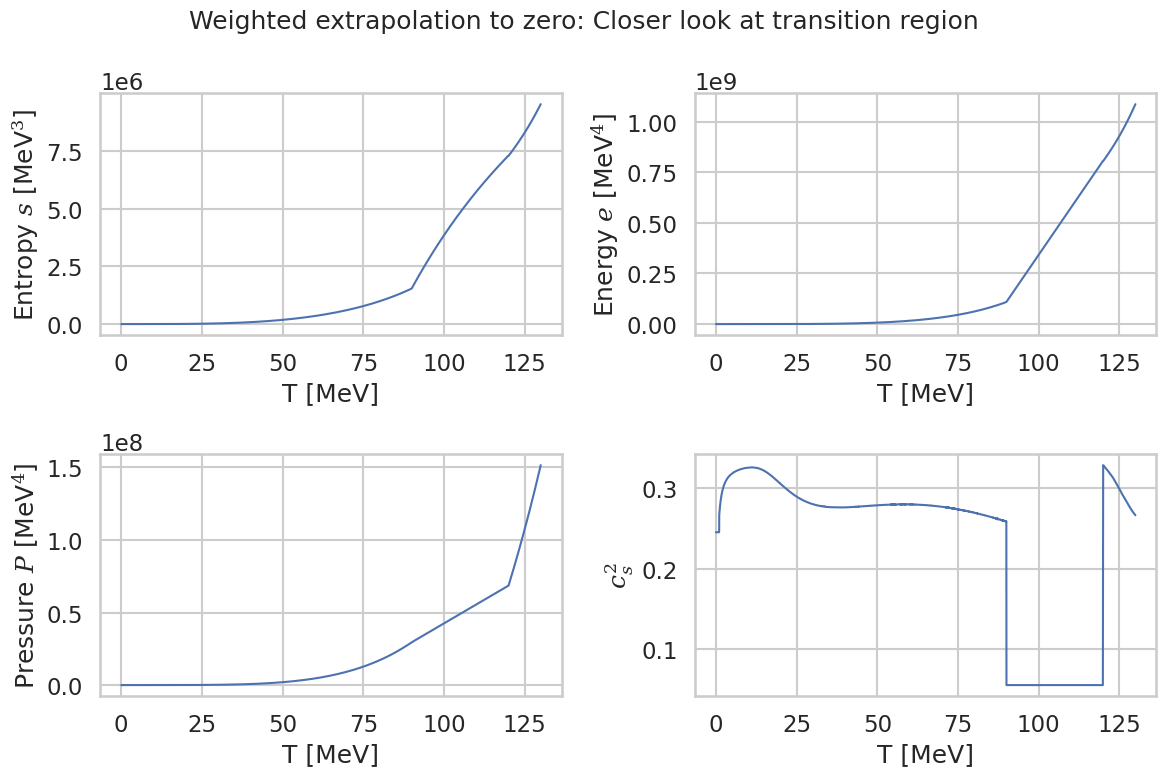

In [87]:
#closer plots

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Weighted extrapolation to zero: Closer look at transition region",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total[:idx_130], s_w_unc[:idx_130], linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total[:idx_130], e_w_unc[:idx_130], linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total[:idx_130], P_w_unc[:idx_130], linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total[:idx_130], cs2_w_unc[:idx_130], linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/Weighted_extrap_uncCloser.png')
plt.show()

### Power law extrap

In [88]:
# Use power law extrapolation
thermo_pwrl_unc = extrap_pwrl.extrapolate_powerlaw(
    T_down=T_point001_down, 
    T_up=T_point01_up, 
    T_total=T_total, 
    cs2_interp=cs2_interp_unc, 
    s_up_interp=s_up_interp_unc, 
    P_up_interp=P_up_interp_unc, 
)

# Access results
P_pwrl_unc = thermo_pwrl_unc['pressure']
e_pwrl_unc = thermo_pwrl_unc['energy'] 
s_pwrl_unc = thermo_pwrl_unc['entropy']
cs2_pwrl_unc = thermo_pwrl_unc['cs2']

In [89]:
sT_pwrl_unc = []
for i, T in enumerate(T_total):
    sT_pwrl_unc.append(s_pwrl_unc[i]*T)

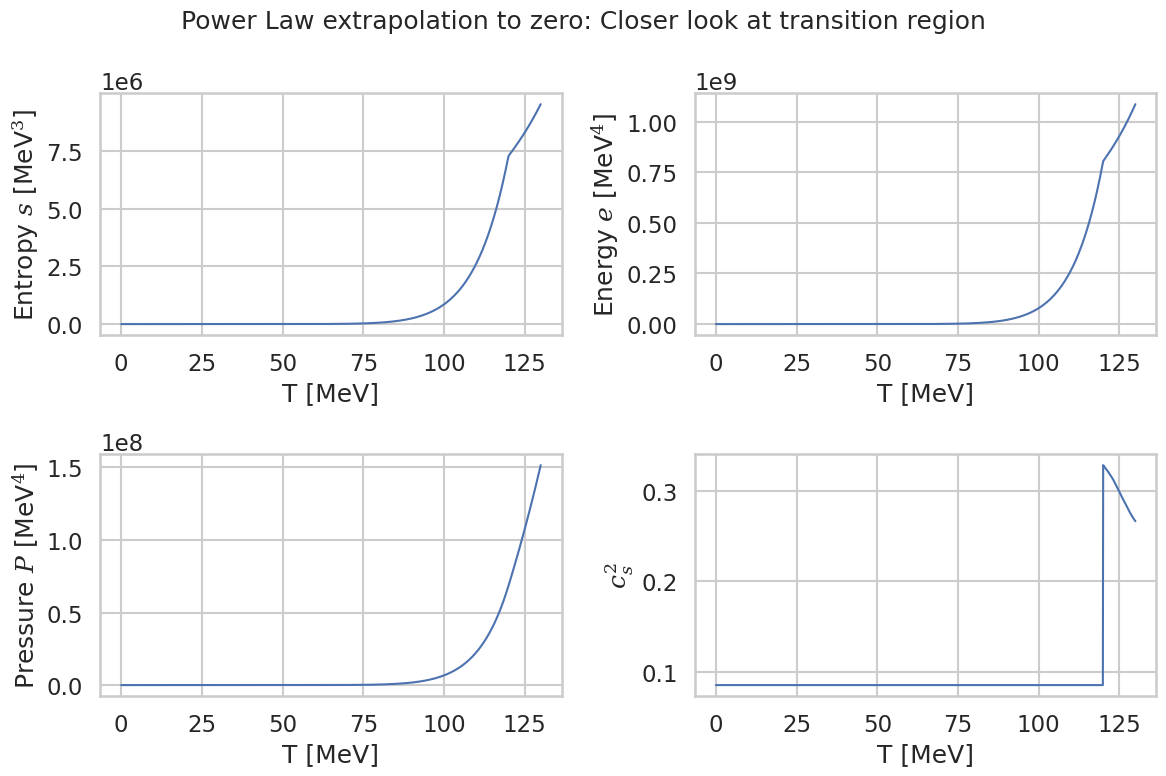

In [90]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Power Law extrapolation to zero: Closer look at transition region",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total[:idx_130], s_pwrl_unc[:idx_130], linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total[:idx_130], e_pwrl_unc[:idx_130], linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total[:idx_130], P_pwrl_unc[:idx_130], linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total[:idx_130], cs2_pwrl_unc[:idx_130], linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/PowerLaw_extrap_uncCloser.png')
plt.show()

### HRG up to Tsw 

In [48]:
# Use weighted extrapolation
thermo_hrg_unc = extrap_hrg.extrapolate_hrg(
    P_down=P_hrgtoTsw,
    P_up = P_up_interp_unc,
    e_down=e_hrgtoTsw,
    e_up=e_up_interp_unc,
    s_down=s_hrgtoTsw,
    s_up=s_up_interp_unc,
    T_total = T_total,
    cs2_interp=cs2_interp_unc,
    idx_Tsw = idx_Tsw,
)

# Access results
P_hrg_unc = thermo_hrg_unc['pressure']
e_hrg_unc = thermo_hrg_unc['energy'] 
s_hrg_unc = thermo_hrg_unc['entropy']
cs2_hrg_unc = thermo_hrg_unc['cs2']

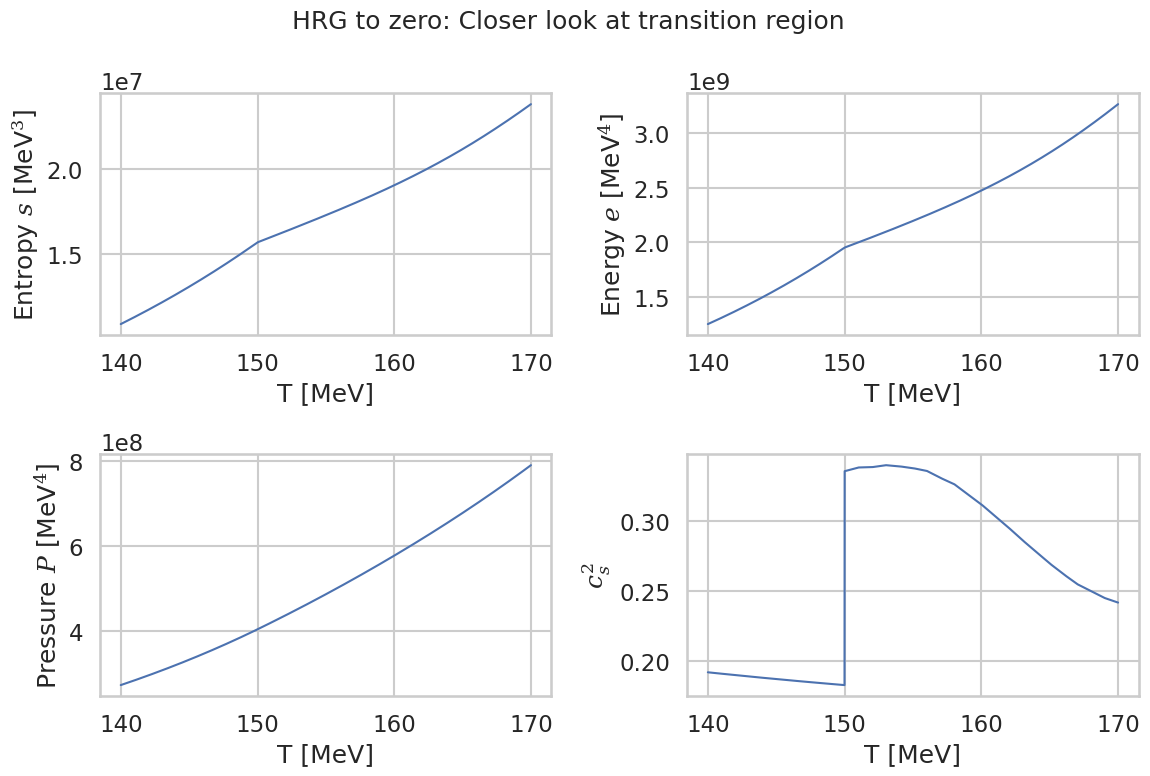

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("HRG to zero: Closer look at transition region",
             fontsize=18)

# ---- Entropy density s ----
axes[0, 0].plot(T_total[idx_140:idx_170], s_hrg_unc[idx_140:idx_170], linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total[idx_140:idx_170], e_hrg_unc[idx_140:idx_170], linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total[idx_140:idx_170], P_hrg_unc[idx_140:idx_170], linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total[idx_140:idx_170], cs2_hrg_unc[idx_140:idx_170], linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig('./images/HRG_extrap_uncCloser.png')
plt.show()

## Saving to files (unconstrained gp)

In [92]:
# for unconstrained GP 

def save_unconstrained_gp_files(sample_idx, l, sigma, mean):
    while True:
        cs2_sample_file = sampler.generate_sample_unconstrained(l=l, sigma=sigma, cte_mean=mean)
        cs2_interp_file = interp1d(T_total_coarse, cs2_sample_file) 

        s_up_file = entropy_up(s_sw, T_sw, cs2_interp_file, T_point01_up)
        P_up_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_file)
        e_up_file = energy_up(s_up_file, P_up_file, T_point01_up)

        #pwr extrap 
        thermo_pwrl_file = extrap_pwrl.extrapolate_powerlaw(
          T_down=T_point001_down, 
          T_up=T_point01_up, 
          T_total=T_total, 
          cs2_interp=cs2_interp_file, 
          s_up_interp=s_up_file, 
          P_up_interp=P_up_file, 
        )

        P_pwrl_file = thermo_pwrl_file['pressure']
        e_pwrl_file = thermo_pwrl_file['energy'] 
        s_pwrl_file = thermo_pwrl_file['entropy']
        cs2_pwrl_file = thermo_pwrl_file['cs2']

        #weighted extrap 
        thermo_w_file = extrap_w.extrapolate_weighted(
          P_down=P_hrg_to110[:idx_90],
          P_up = P_up_file(T_point01_up),
          e_down=e_hrg_to110[:idx_90],
          e_up = e_up_file(T_point01_up),
          T_up = T_point01_up,
          T_total=T_total, 
          cs2_interp=cs2_interp_file, 
          n_transition=len_transition_unc,
          endpointIdx = idx_120
        )    

        P_w_file = thermo_w_file['pressure']
        e_w_file = thermo_w_file['energy'] 
        s_w_file = thermo_w_file['entropy']
        cs2_w_file = thermo_w_file['cs2']
        adjusted_transition_P = thermo_w_file["adjusted_transition_P"]
        adjusted_transition_e = thermo_w_file["adjusted_transition_e"]

        cs2_region = thermo_w_file['cs2'][idx_110:idx_120]

        if adjusted_transition_P != adjusted_transition_e:
           print("Rejected sample: transition width adjusted")
           continue

        if np.any((cs2_region < 0) | (cs2_region > 1.0001)):
           print("Rejected sample: cs2 out of bounds in transition region")
           continue

        #hrg to 150 vectors
        thermo_hrg_file = extrap_hrg.extrapolate_hrg(
          P_down=P_hrgtoTsw,
          P_up = P_up_file,
          e_down=e_hrgtoTsw,
          e_up=e_up_file,
          s_down=s_hrgtoTsw,
          s_up=s_up_file,
          T_total = T_total,
          cs2_interp=cs2_interp_file,
          idx_Tsw = idx_Tsw,
        )   

        P_hrg_file = thermo_hrg_file['pressure']
        e_hrg_file = thermo_hrg_file['energy'] 
        s_hrg_file = thermo_hrg_file['entropy']
        cs2_hrg_file = thermo_hrg_file['cs2']

        with open(f"./eosDataFiles/unconstrained/l{l}_s{sigma}/eos_pwr_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(e_pwrl_file)}\n")
            for e, T, p, cs2, s in zip(e_pwrl_file, T_total, P_pwrl_file, cs2_pwrl_file, s_pwrl_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./eosDataFiles/unconstrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(e_w_file)}\n")
            for e, T, p, cs2, s in zip(e_w_file, T_total, P_w_file, cs2_w_file, s_w_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./eosDataFiles/unconstrained/l{l}_s{sigma}/eos_hrg_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(e_hrg_file)}\n")
            for e, T, p, cs2, s in zip(e_hrg_file, T_total, P_hrg_file, cs2_hrg_file, s_hrg_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n") 
    
        print("accepted sample saved")
        break

In [93]:
for i in range(0, 10):
    save_unconstrained_gp_files(sample_idx=i, l=400, sigma=15, mean=0.3) 

/home/luizaperin/codes/gp/extrapolation_weighted.py:146: RuntimeWarning: invalid value encountered in divide
  s_total = np.where(T_total != 0, (P_total + e_total) / T_total, 0.0)


accepted sample saved
accepted sample saved
accepted sample saved
accepted sample saved
accepted sample saved
accepted sample saved
accepted sample saved
accepted sample saved
accepted sample saved
accepted sample saved


## Cs² via jackknife samples

In [52]:
import jk
importlib.reload(jk)
from jk import generate_jackknife_samples, jackknife_statistics

In [53]:
jk_stats = jackknife_statistics(data)
cov_matrix = jk_stats['cov_matrix']
jk_mean = jk_stats['mean']

n_samples = 20

jk_samples = generate_jackknife_samples(n_samples, jk_mean, cov_matrix)

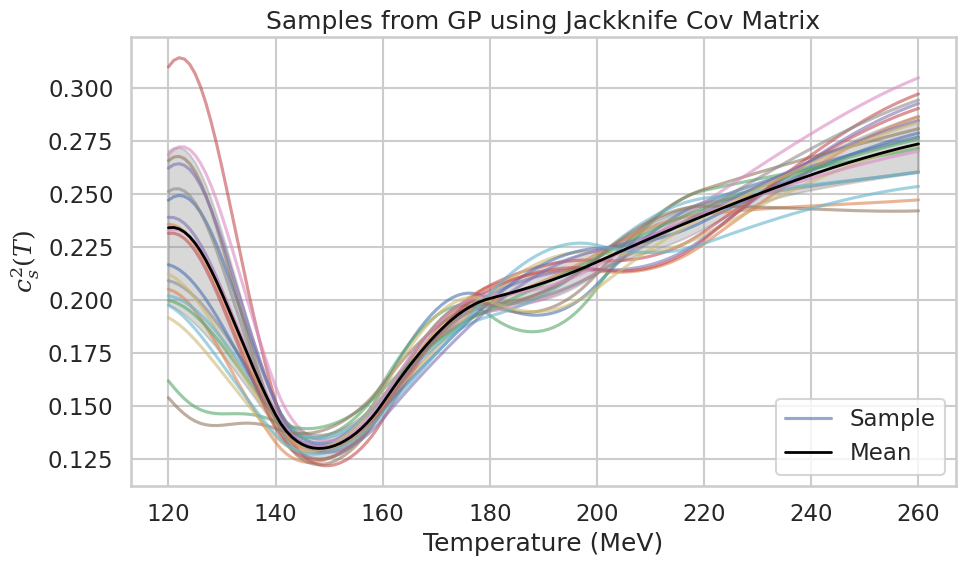

In [54]:
## Pwr law extrapolation

plt.figure(figsize=(10, 6))
for i in range(n_samples):
    plt.plot(T_coarse, jk_samples[i], alpha=0.6, label=f'Sample' if i == 0 else None)

# Plot the mean and uncertainty band
std_diag = np.sqrt(np.diag(cov_matrix))
plt.plot(T_coarse, jk_mean, color='black', lw=2, label='Mean')
plt.fill_between(T_coarse, jk_mean - std_diag, jk_mean + std_diag, color='gray', alpha=0.3)

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('./images/cs2_from_jk.png')
plt.show()

## Extrapolating to high and low T

In [55]:
from jk import jkSamples_interp
from jk import cs2_powerlaw, cs2_tanh, cs2_exp

In [56]:
jk_interp = jkSamples_interp(n_samples, T_coarse, jk_samples)

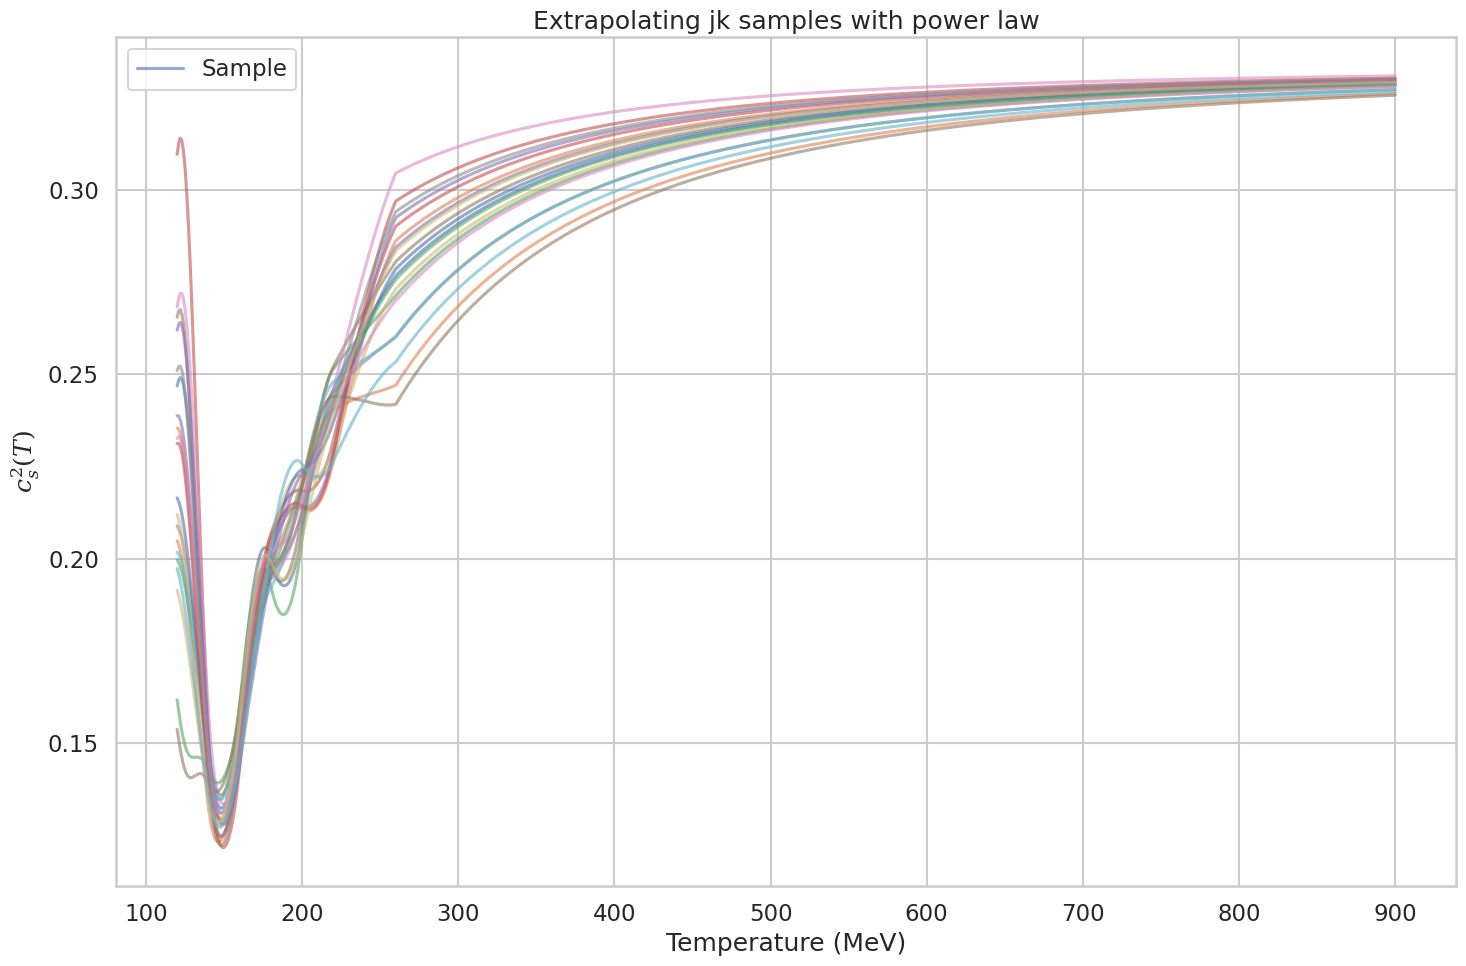

In [57]:
# pwr law 

for i in range(n_samples):
    plt.plot(
        T_point01_up,
        cs2_powerlaw(T_point01_up, T0=260.0, interp=jk_interp[i]),
        alpha=0.6,
        label="Sample" if i == 0 else None
    )

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Extrapolating jk samples with power law')
plt.legend()
plt.grid(True)
plt.savefig('./images/cs2_interp_jk_pwr.png')
plt.tight_layout()

plt.show()

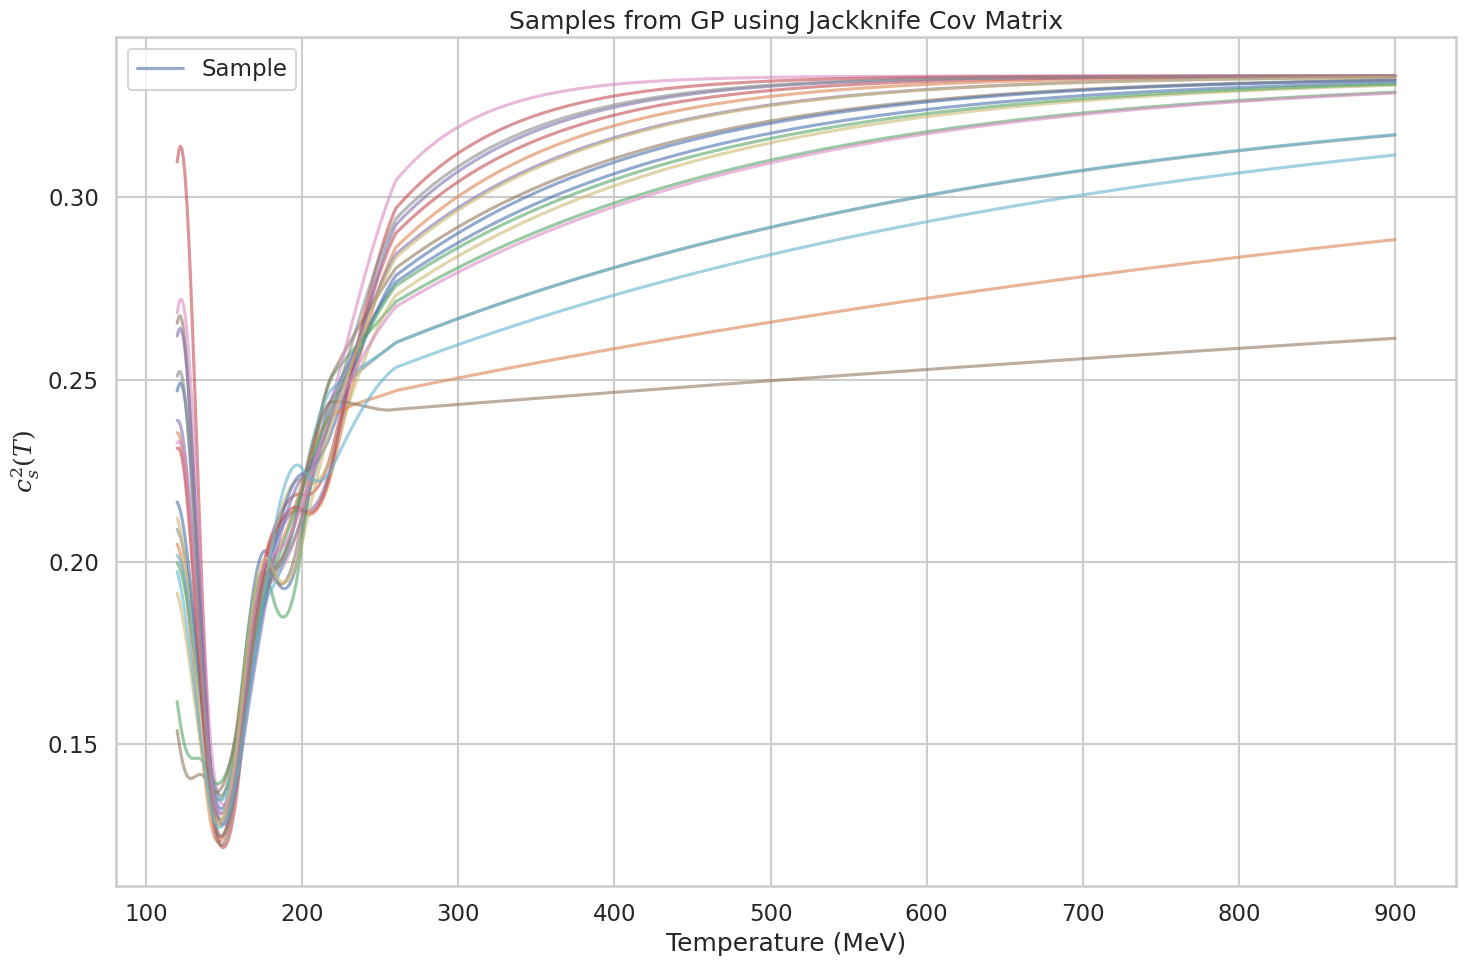

In [58]:
#using exponential extrapolation

for i in range(n_samples):

    cs2_expExtrap = cs2_exp(T_point01_up, interp=jk_interp[i], T0=260.0)

    plt.plot(
        T_point01_up,
        cs2_expExtrap(T_point01_up),
        alpha=0.6,
        label="Sample" if i == 0 else None
    )

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/cs2_interp_jk_expExtrap.png')

plt.show()

### Downwards extrap as HRG below 150 MeV

In [59]:
s_up_jk = entropy_up(s_sw, T_sw, cs2_expExtrap, T_point01_up)
P_up_jk = pressure_up(P_sw, T_sw, T_point01_up, s_up_jk)
e_up_jk = energy_up(s_up_jk, P_up_jk, T_point01_up)

In [60]:

thermo_hrg_jk = extrap_hrg.extrapolate_hrg(
          P_down=P_hrgtoTsw,
          P_up = P_up_jk,
          e_down=e_hrgtoTsw,
          e_up=e_up_jk,
          s_down=s_hrgtoTsw,
          s_up=s_up_jk,
          T_total = T_total,
          cs2_interp=cs2_expExtrap,
          idx_Tsw = idx_Tsw,
        ) 

P_hrg_jk = thermo_hrg_jk['pressure']
e_hrg_jk = thermo_hrg_jk['energy']
s_hrg_jk = thermo_hrg_jk['entropy'] 
cs2_hrg_jk = thermo_hrg_jk['cs2']

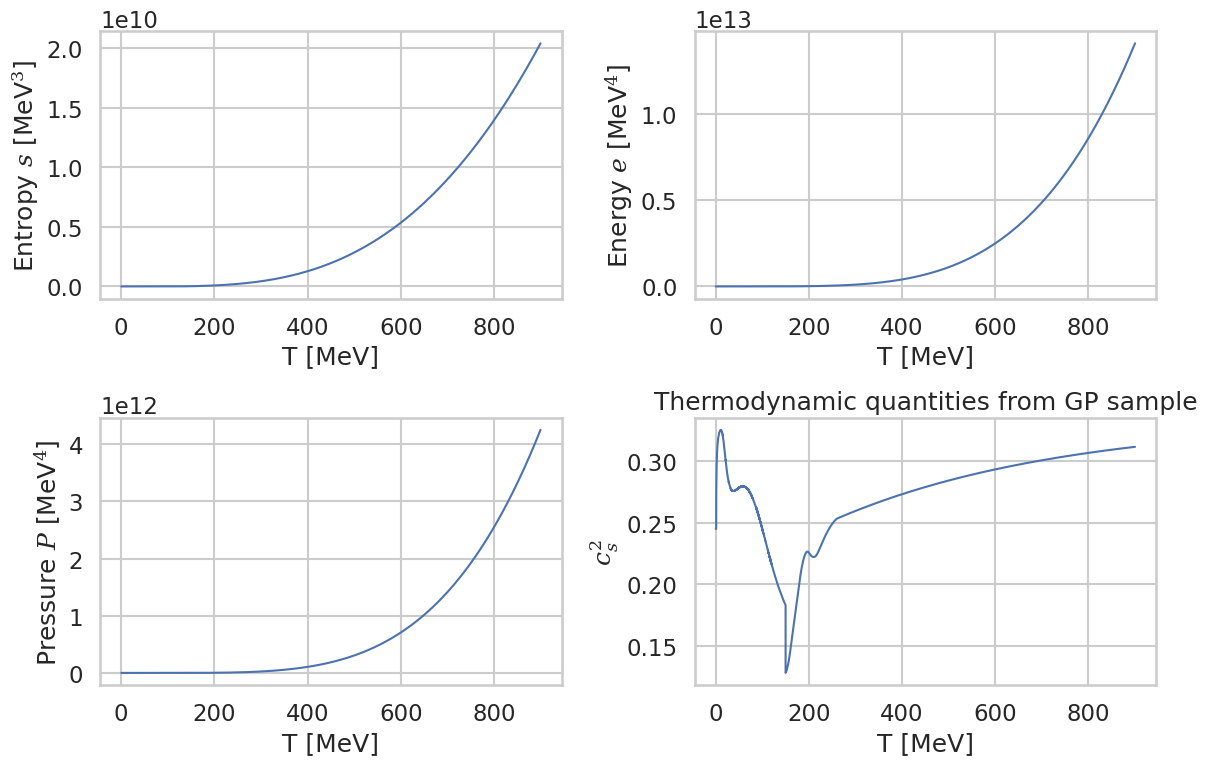

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# ---- Entropy density s ----
axes[0, 0].plot(T_total, s_hrg_jk, linewidth=1.5)
axes[0, 0].set_xlabel('T [MeV]')
axes[0, 0].set_ylabel(r'Entropy $s$ [MeV$^3$]')
axes[0, 0].grid(True)

# ---- Energy density e ----
axes[0, 1].plot(T_total, e_hrg_jk, linewidth=1.5)
axes[0, 1].set_xlabel('T [MeV]')
axes[0, 1].set_ylabel(r'Energy $e$ [MeV$^4$]')
axes[0, 1].grid(True)

# ---- Pressure P ----
axes[1, 0].plot(T_total, P_hrg_jk, linewidth=1.5)
axes[1, 0].set_xlabel('T [MeV]')
axes[1, 0].set_ylabel(r'Pressure $P$ [MeV$^4$]')
axes[1, 0].grid(True)

# ---- Speed of sound squared cs2 ----
axes[1, 1].plot(T_total, cs2_hrg_jk, linewidth=1.5)
axes[1, 1].set_xlabel('T [MeV]')
axes[1, 1].set_ylabel(r'$c_s^2$')
axes[1, 1].grid(True)

plt.tight_layout()
plt.title("Thermodynamic quantities from GP sample")
plt.savefig('./images/jk_samples.png')
plt.show()

### Saving to a file

In [62]:
def save_jk_gp_files(i, m, cs2_interp=None):
    
    s_up_jk_file = entropy_up(s_sw, T_sw, cs2_interp, T_point01_up)
    P_up_jk_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_jk_file)
    e_up_jk_file = energy_up(s_up_jk_file, P_up_jk_file, T_point01_up)
    
    #hrg to 150
    thermo_hrg_jk_file = extrap_hrg.extrapolate_hrg(
          P_down=P_hrgtoTsw,
          P_up = P_up_jk_file,
          e_down=e_hrgtoTsw,
          e_up=e_up_jk_file,
          s_down=s_hrgtoTsw,
          s_up=s_up_jk_file,
          T_total = T_total,
          cs2_interp=cs2_interp,
          idx_Tsw = idx_Tsw,
        ) 

    P_hrg_jk = thermo_hrg_jk_file['pressure']
    e_hrg_jk = thermo_hrg_jk_file['energy']
    s_hrg_jk = thermo_hrg_jk_file['entropy'] 
    cs2_hrg_jk = thermo_hrg_jk_file['cs2'] 
    

    with open(f"./data_files/jk_samples/eos_jk_run{m}_s{i}.dat", "w") as f:
        f.write(f"{len(P_hrg_jk)}\n")
        for e, T, p, cs2, s in zip(e_hrg_jk, T_total, P_hrg_jk, cs2_hrg_jk, s_hrg_jk):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")


In [63]:
#changes distribution, every time this is run, change m to inidicate different set

jk_cs2 = multivariate_normal(mean=jk_mean, cov=cov_matrix, size=n_samples)

cs2_interp_jk = []

m = 2

In [64]:
""" for i in range(n_samples):
    
    cs2_expExtrap = cs2_exp(T_point01_up, interp=jk_interp[i], T0=260.0)
    
    save_jk_gp_files(i, m, cs2_interp=cs2_expExtrap) """

' for i in range(n_samples):\n\n    cs2_expExtrap = cs2_exp(T_point01_up, interp=jk_interp[i], T0=260.0)\n\n    save_jk_gp_files(i, m, cs2_interp=cs2_expExtrap) '

## PCA

In [65]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [66]:
N = 500
samples_cs2_GP = []
samples_cs2_interp = []
samples_s = []
samples_P = []
samples_e = []

for _ in range(N):
    cs2_GP = sampler.generate_sample(400, 10)
    cs2_interp_sample = interp1d(T_total_coarse, cs2_GP) 

    s_up_sample = entropy_up(s_sw, T_sw, cs2_interp_sample, T_point01_up)
    P_up_sample = pressure_up(P_sw, T_sw, T_point01_up, s_up_sample)
    e_up_sample = energy_up(s_up_sample, P_up_sample, T_point01_up)
    
    samples_cs2_GP.append(cs2_GP)
    samples_cs2_interp.append(cs2_interp_sample(T_point01_up))
    samples_s.append(s_up_sample(T_point01_up))
    samples_P.append(P_up_sample(T_point01_up))
    samples_e.append(e_up_sample(T_point01_up))
    #print(f"Generated sample {_+1}/{N}")

samples_cs2_GP = np.array(samples_cs2_GP)
samples_cs2_interp = np.array(samples_cs2_interp)
samples_s = np.array(samples_s)
samples_P = np.array(samples_P)
samples_e = np.array(samples_e)

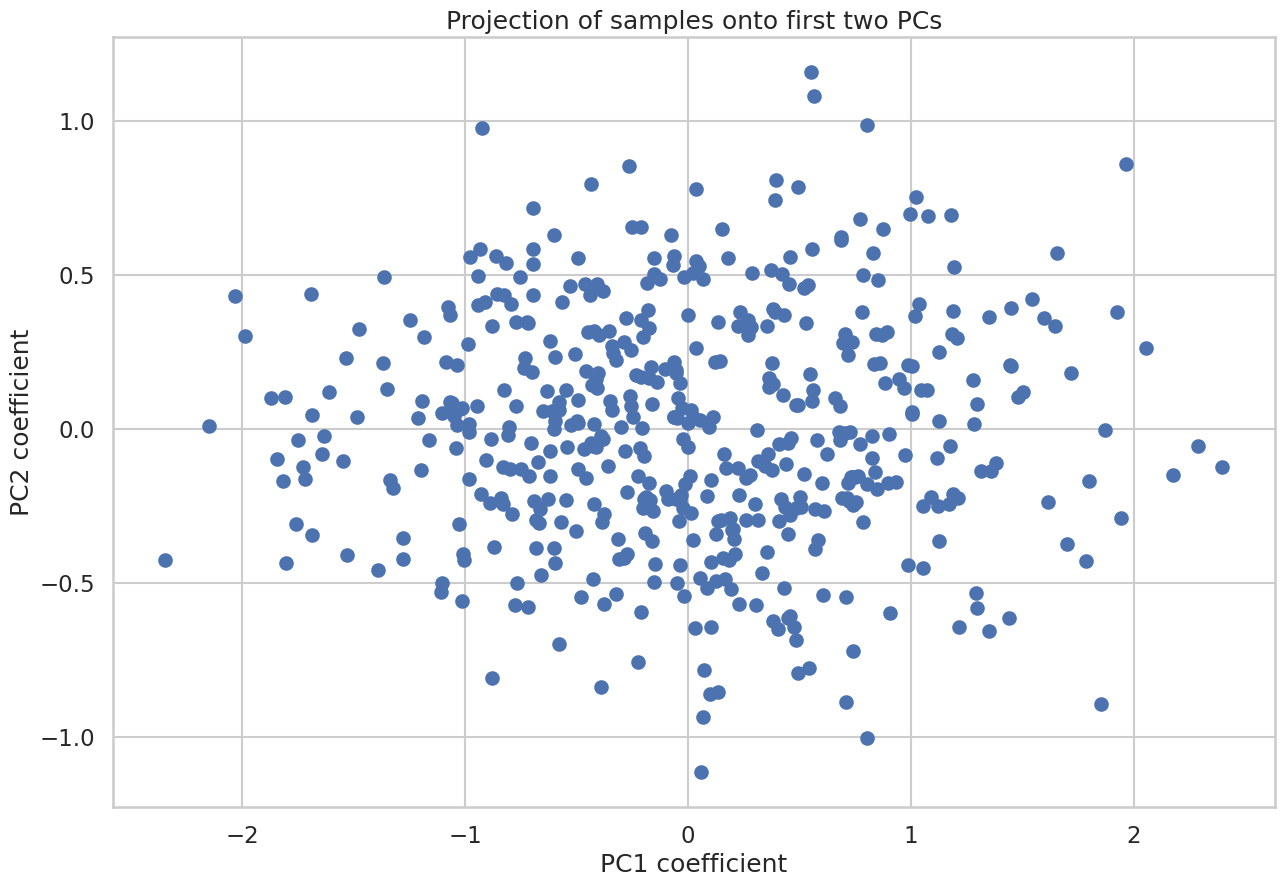

In [67]:
pca = PCA() 
#already subtracted mean, so no need to center again
#n_components not set so all components are kept

coeff = pca.fit_transform(samples_cs2_GP) #learns pca basis and projects data onto it

PCs = pca.components_ #eigenvectors
eigenvals = pca.explained_variance_ #the amount of variance explained by each of the selected components (eigenvalues)

var_fraction = pca.explained_variance_ratio_

plt.scatter(coeff[:,0], coeff[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs")
plt.savefig("./images/pca_projection_cs2.png")
plt.show()

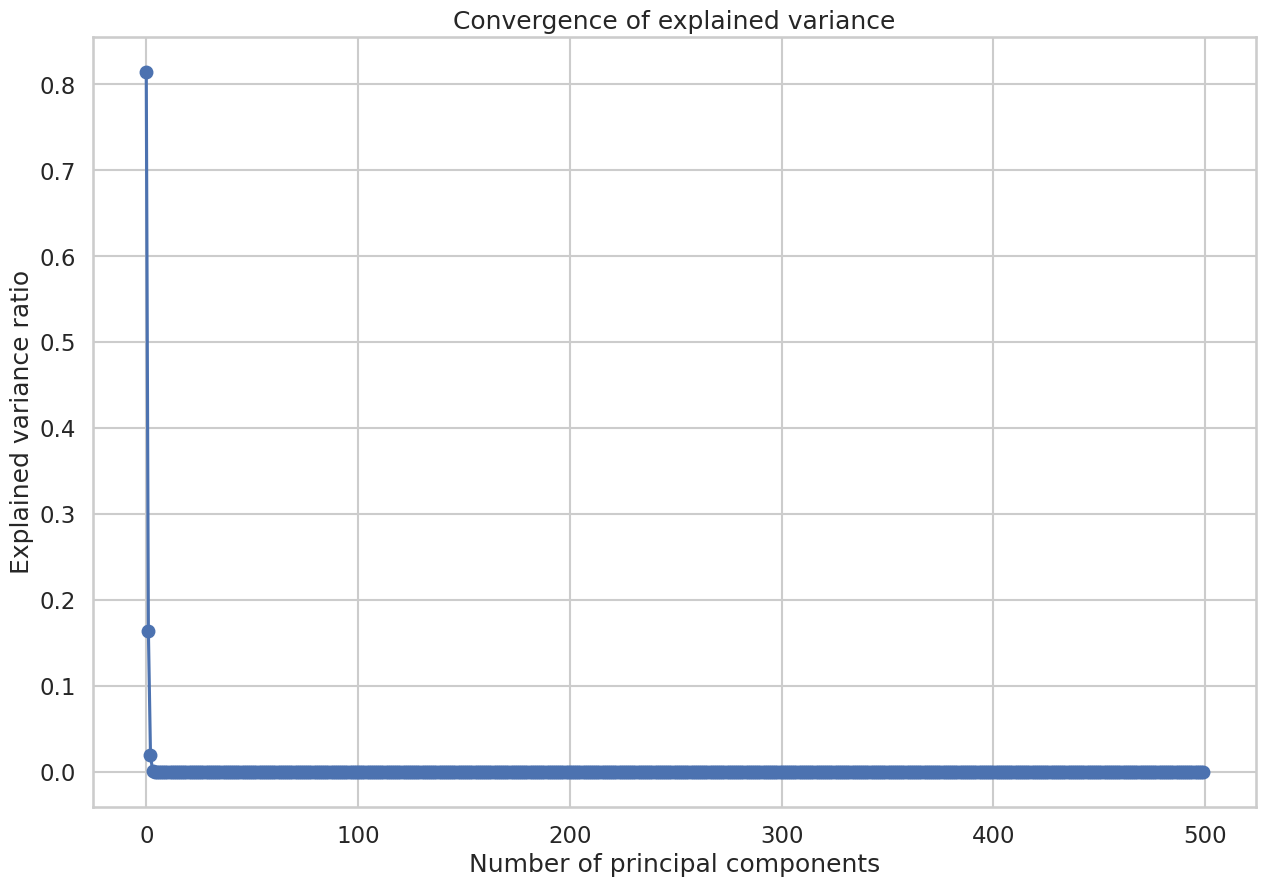

In [68]:
plt.plot(var_fraction, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance ratio")
plt.title("Convergence of explained variance")
plt.savefig("./images/pca_explained_variance_cs2_l100.png")
plt.show()

/tmp/ipykernel_170504/4111971457.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


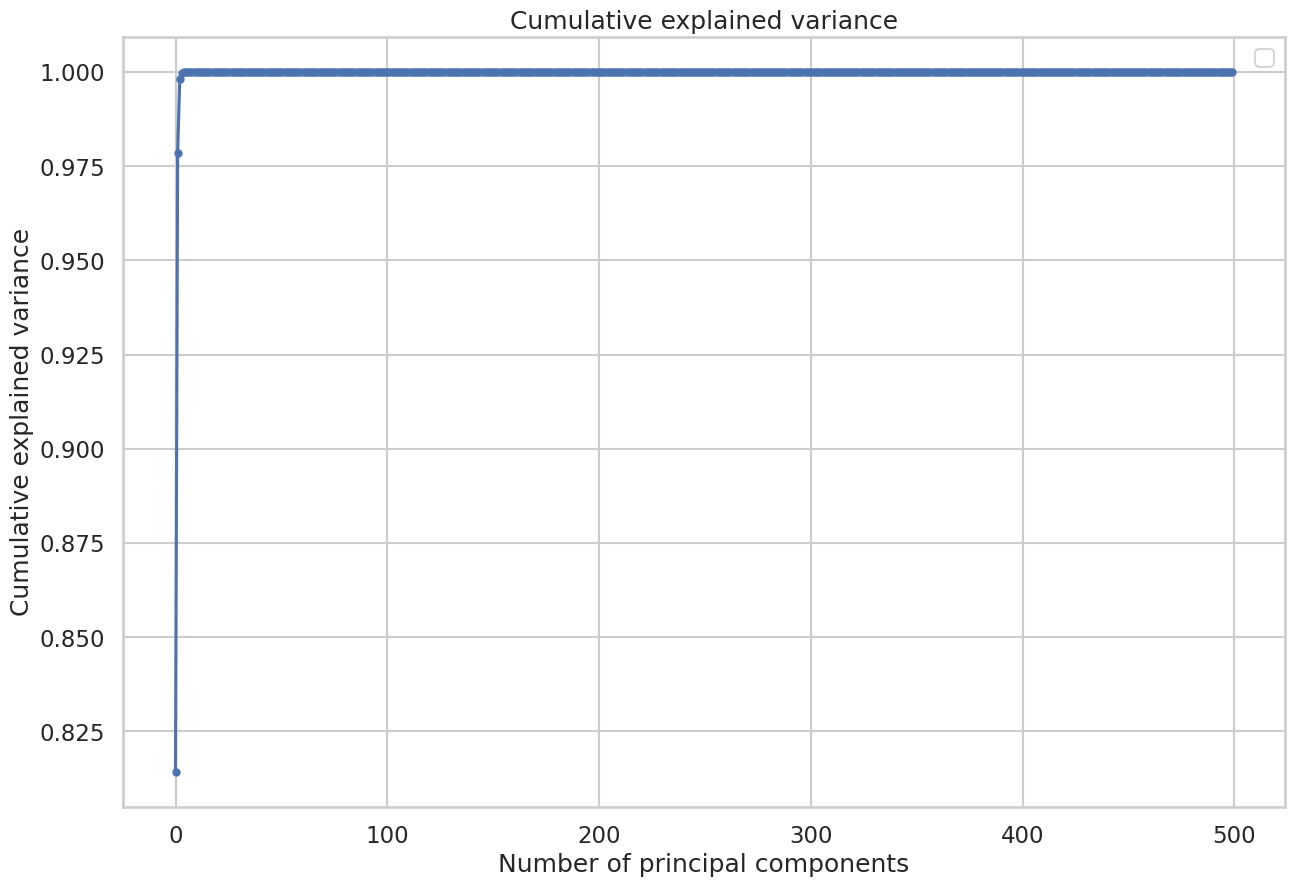

In [69]:
#cumulative variance
cumulative_variance = np.cumsum(var_fraction)
plt.plot(cumulative_variance, marker='o', markersize=5)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")
plt.legend()
plt.savefig("./images/pca_cumulative_variance_cs2_l100.png")
plt.show()

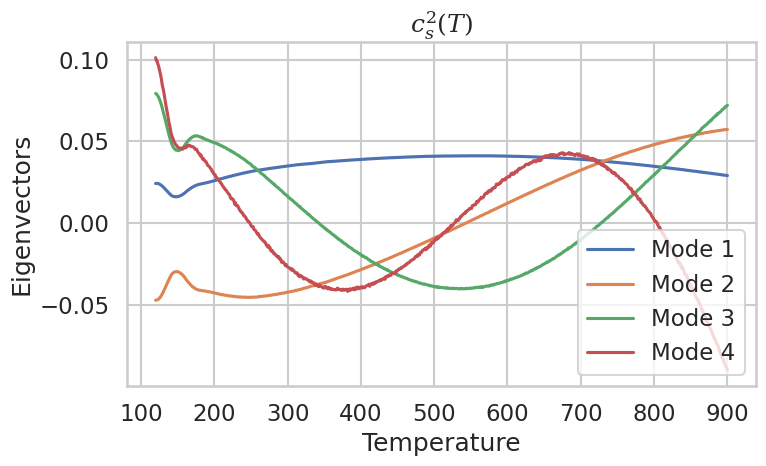

In [71]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_total_coarse[::], PCs[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvectors")
plt.title("$c_s^2(T)$")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_cs2.png")
plt.show()

Max abs diff: 1.1102230246251565e-16
All close: True


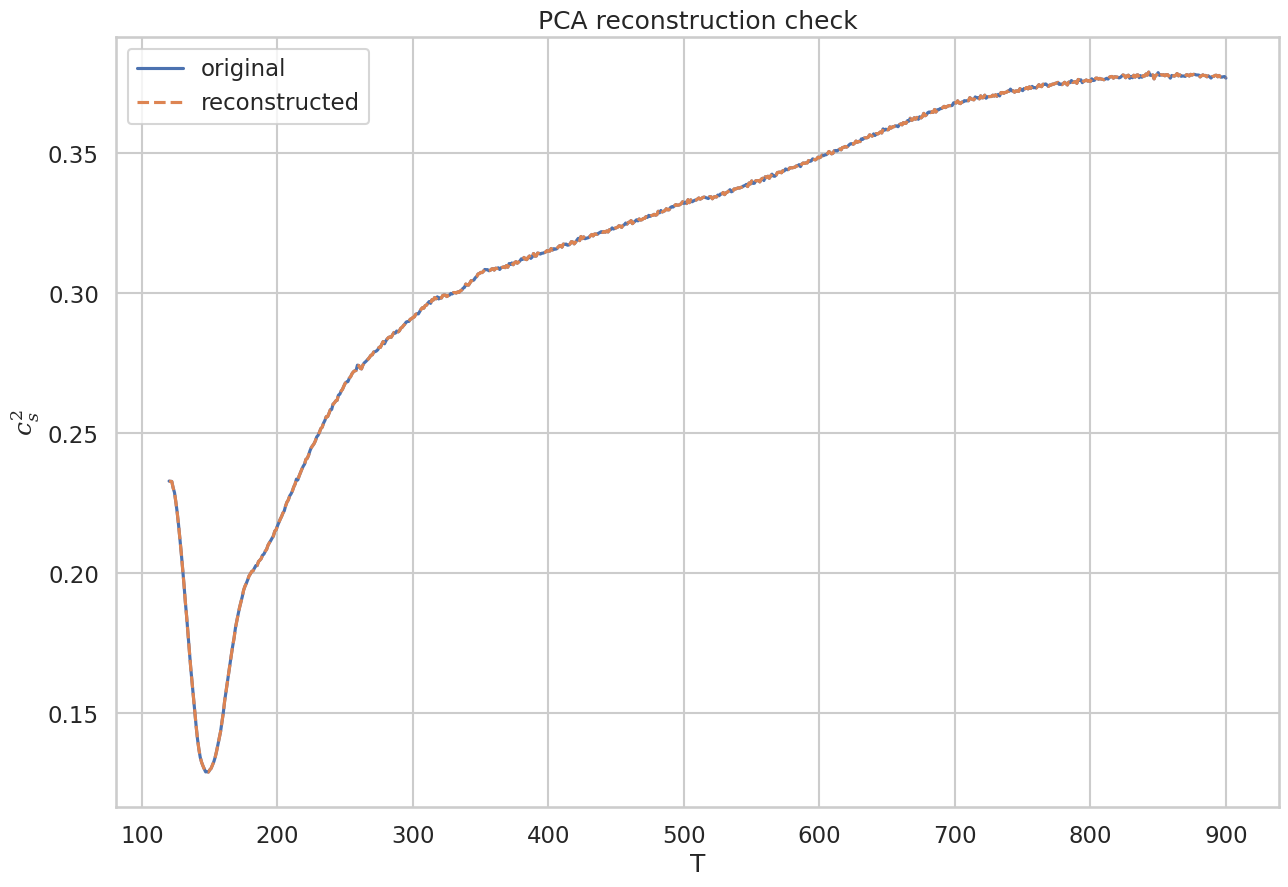

In [72]:
i = 0

original = samples_cs2_GP[i]
reconstructed = pca.inverse_transform(coeff)[i]

print("Max abs diff:", np.max(np.abs(original - reconstructed)))
print("All close:", np.allclose(original, reconstructed))

plt.plot(T_total_coarse, original, label="original")
plt.plot(T_total_coarse, reconstructed, "--", label="reconstructed")

plt.xlabel("T")
plt.ylabel("$c_s^2$")
plt.title("PCA reconstruction check")
plt.legend()
plt.show()

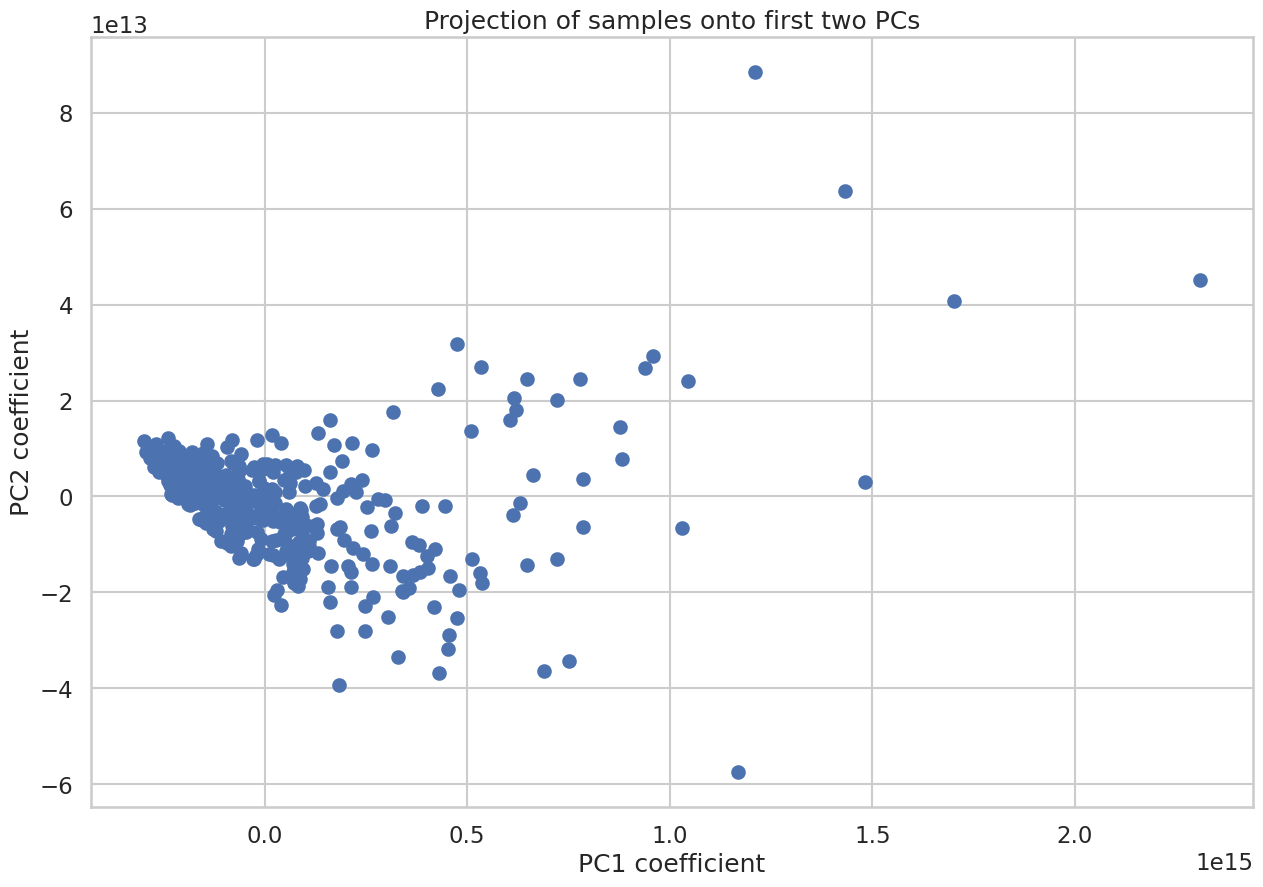

In [73]:
#Pressure

samples_P = samples_P[:, ::]
pca_P = PCA() 
#already subtracted mean, so no need to center again
#n_components is not set: all components are kept

coeff_P = pca_P.fit_transform(samples_P) #learns pca basis and projects data onto it

PCs_P = pca_P.components_
eigenvals_P = pca_P.explained_variance_
var_fraction_P = pca_P.explained_variance_ratio_

plt.scatter(coeff_P[:,0], coeff_P[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs")
plt.savefig("./images/pca_projection_P.png")
plt.show()

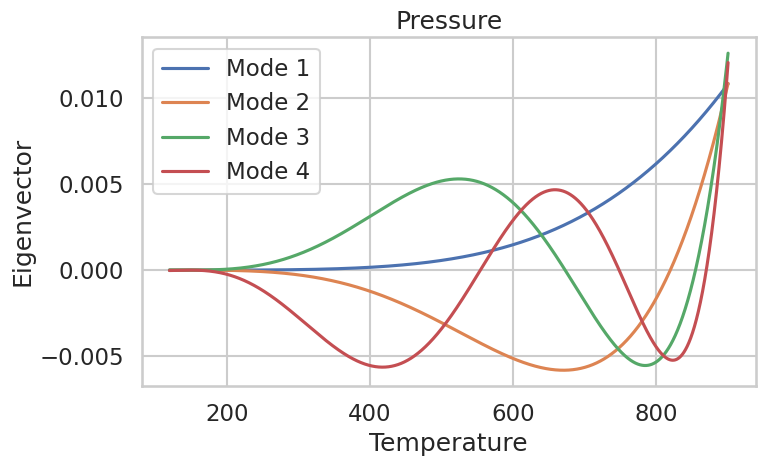

In [74]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_point01_up[::], PCs_P[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvector")
plt.title("Pressure")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_P.png")
plt.show()

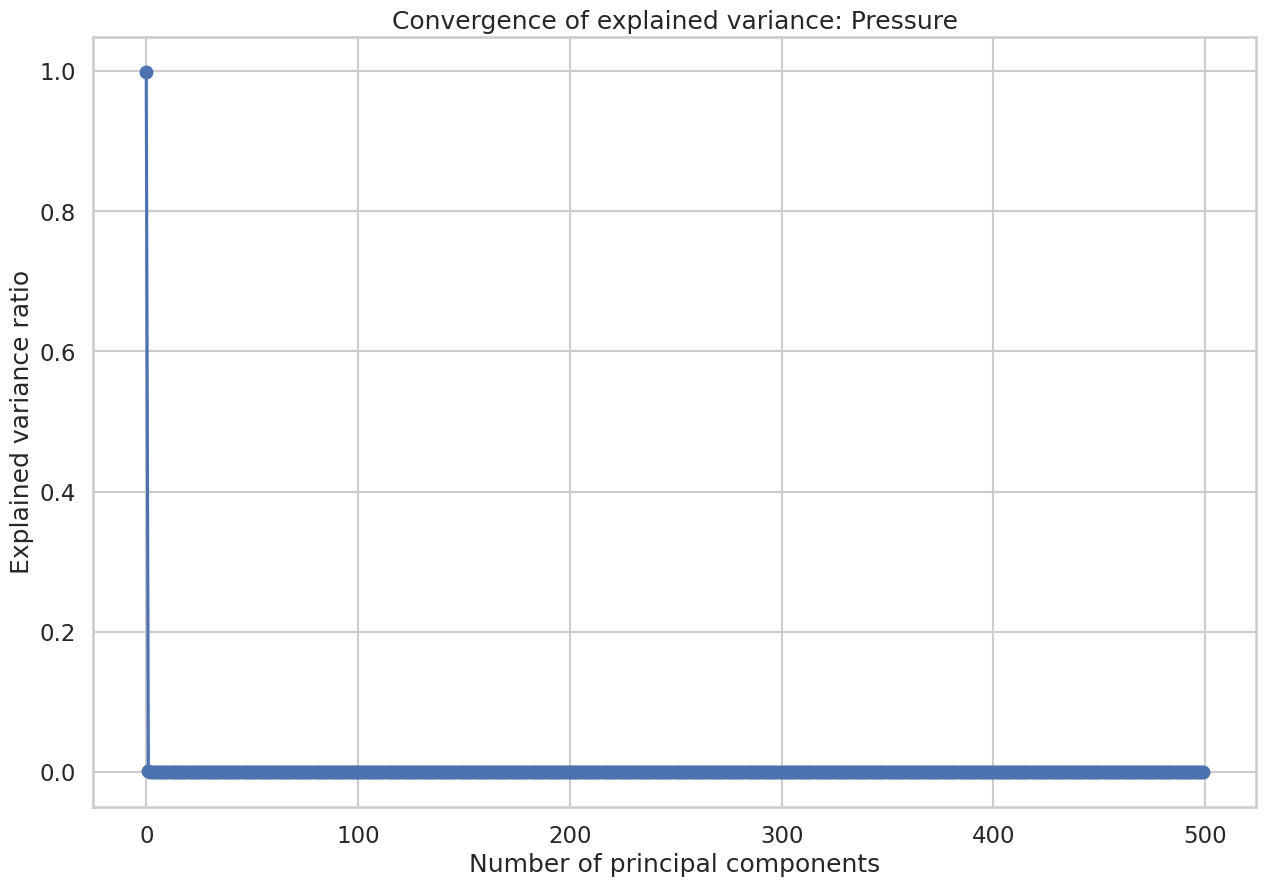

In [75]:
plt.plot(var_fraction_P, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance ratio")
plt.title("Convergence of explained variance: Pressure")
plt.savefig("./images/pca_explained_variance_P.png")
plt.show()

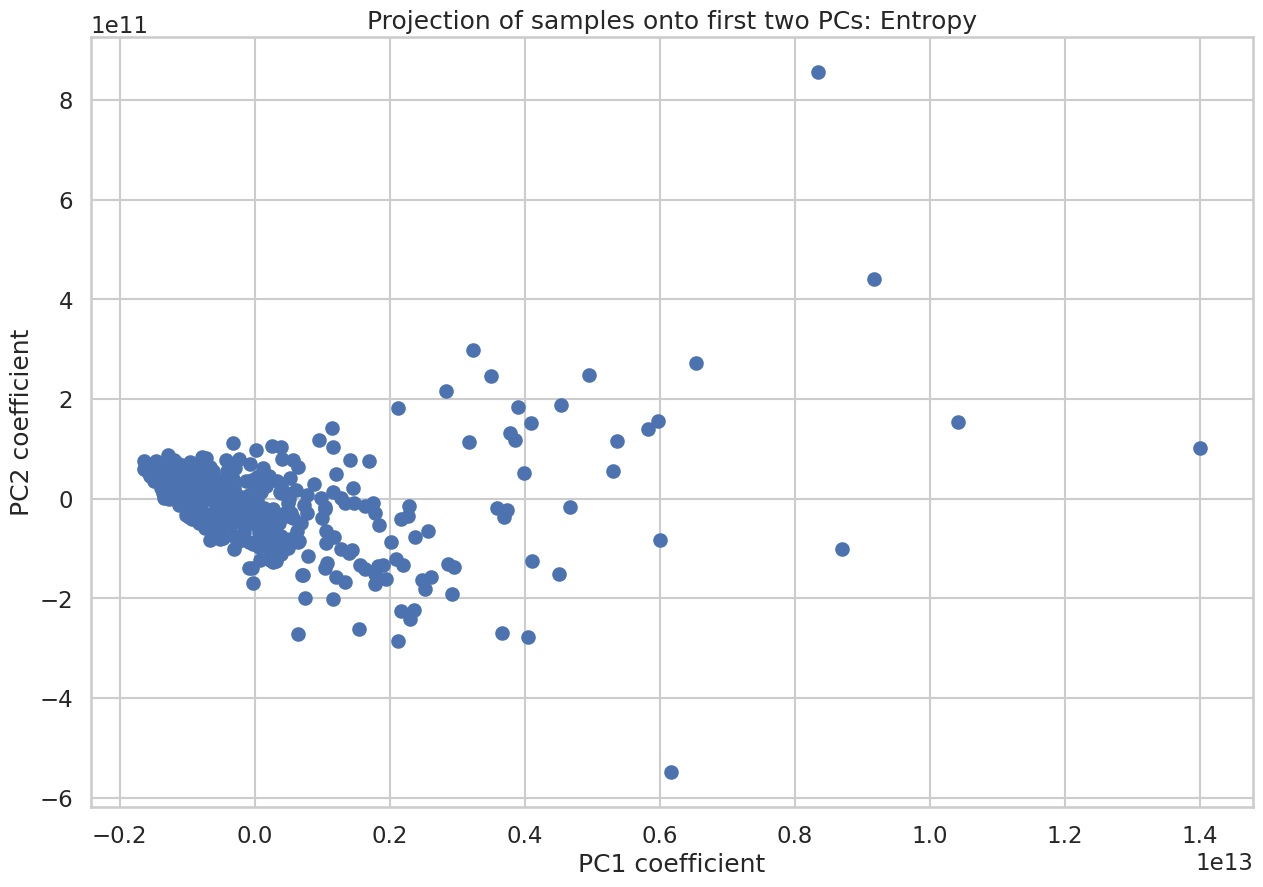

In [76]:
#entropy

pca_s = PCA()
coeff_s = pca_s.fit_transform(samples_s)
PCs_s = pca_s.components_
eigvals_s = pca_s.explained_variance_
var_fraction_s = pca_s.explained_variance_ratio_

plt.scatter(coeff_s[:,0], coeff_s[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs: Entropy")
plt.savefig("./images/pca_projection_s.png")
plt.show()

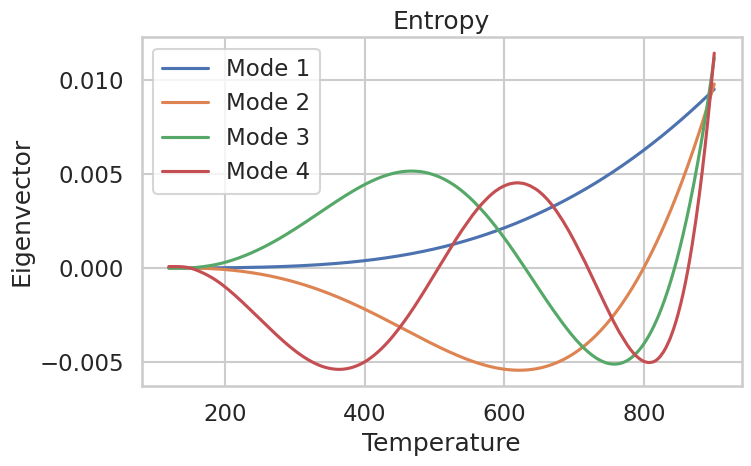

In [77]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_point01_up[::], PCs_s[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvector")
plt.title("Entropy")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_s.png")
plt.show()

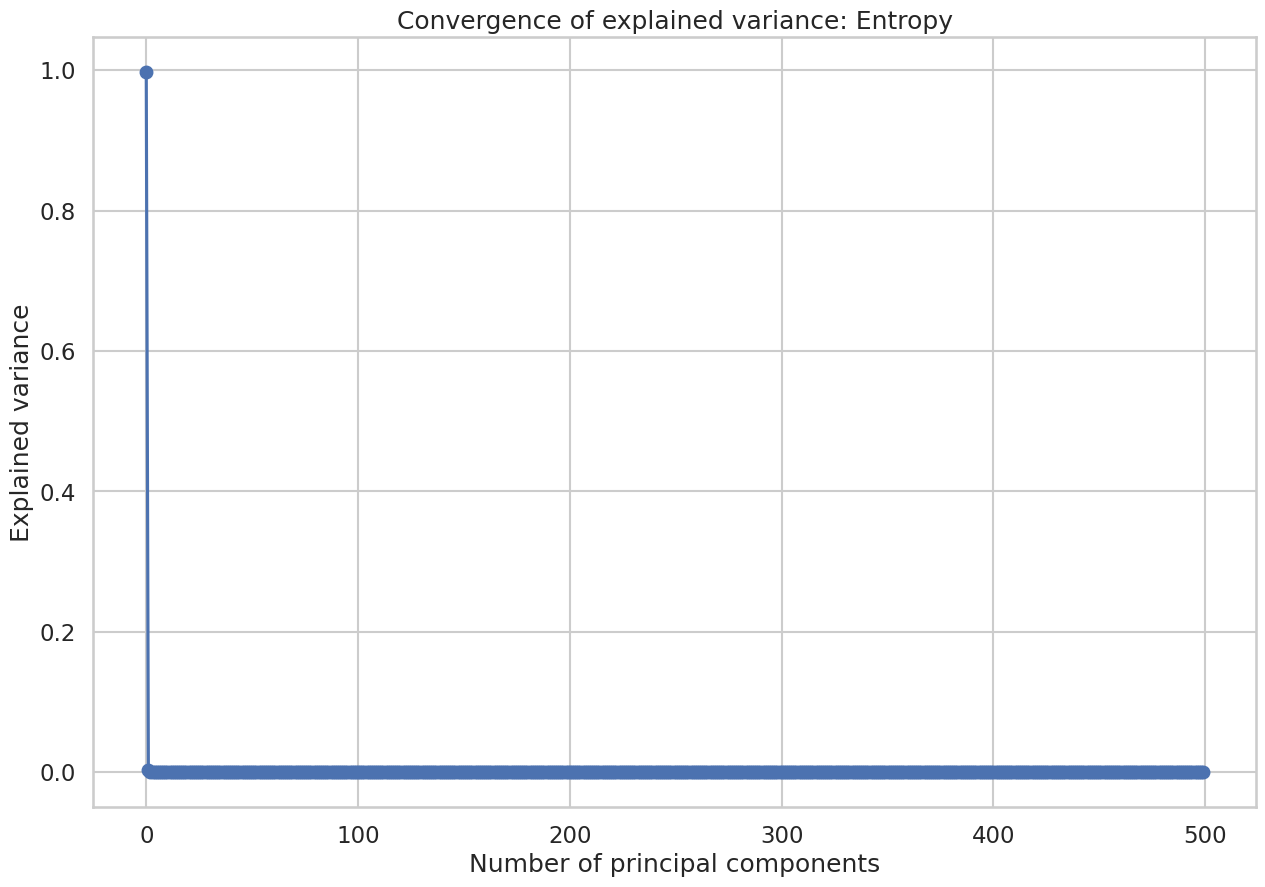

In [78]:
plt.plot(var_fraction_s, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance")
plt.title("Convergence of explained variance: Entropy")
plt.savefig("./images/pca_explained_variance_s.png")
plt.show()

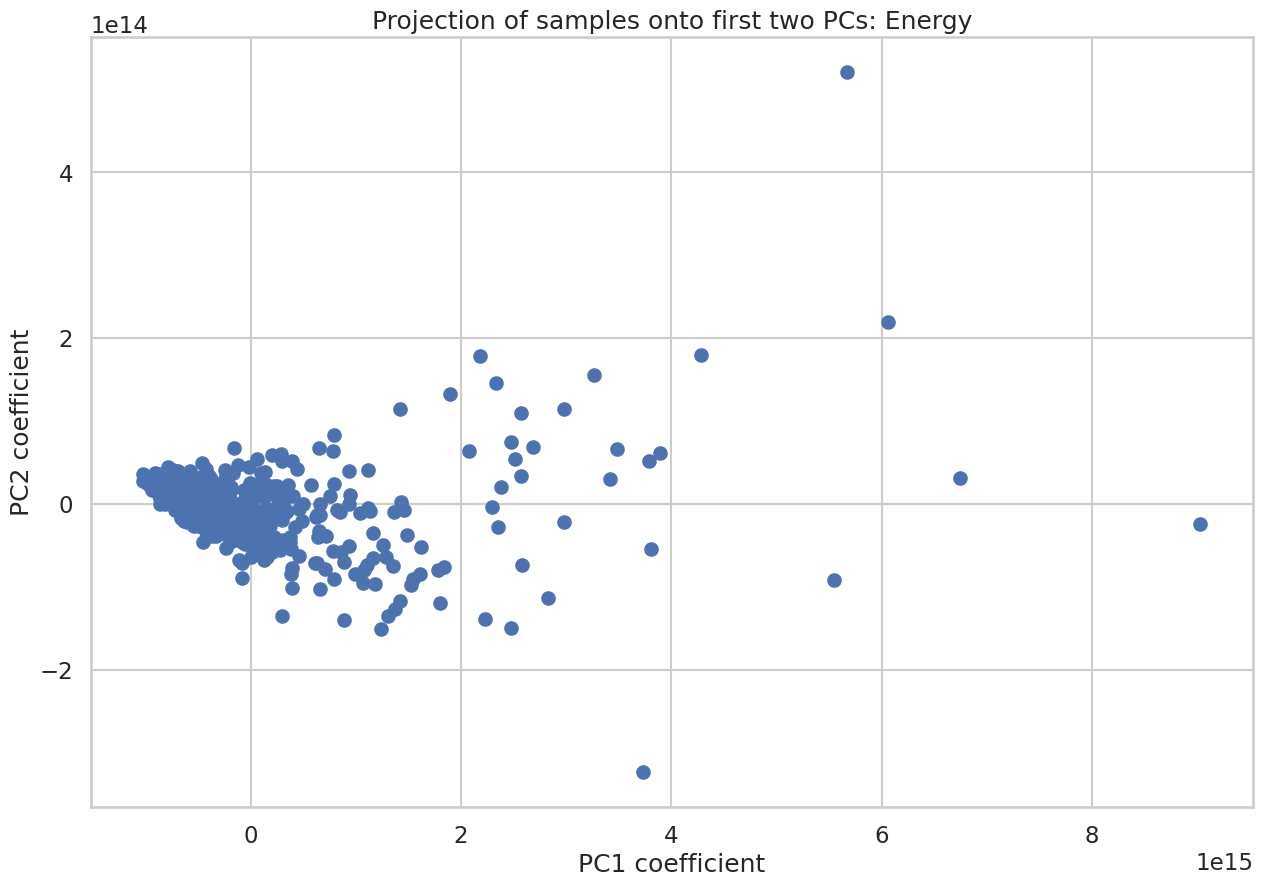

In [79]:
#energy

pca_e = PCA()
coeff_e = pca_e.fit_transform(samples_e)    
PCs_e = pca_e.components_
eigenvals_e = pca_e.explained_variance_
var_fraction_e = pca_e.explained_variance_ratio_

plt.scatter(coeff_e[:,0], coeff_e[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs: Energy")
plt.savefig("./images/pca_projection_e.png")
plt.show()

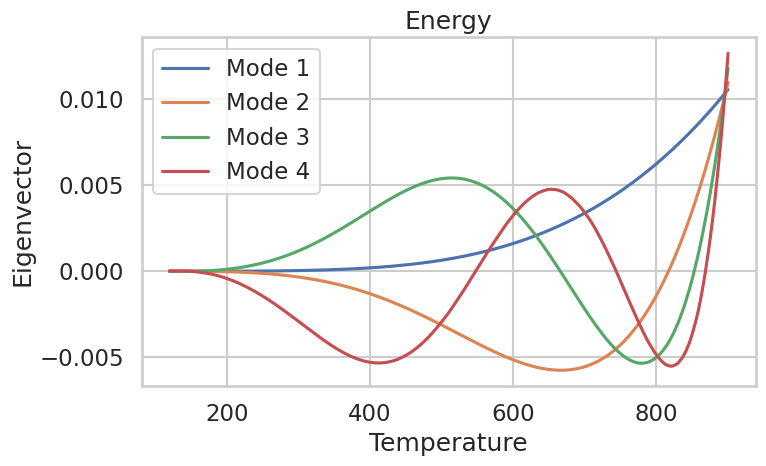

In [80]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_point01_up[::], PCs_e[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvector")
plt.title("Energy")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_e.png")
plt.show()

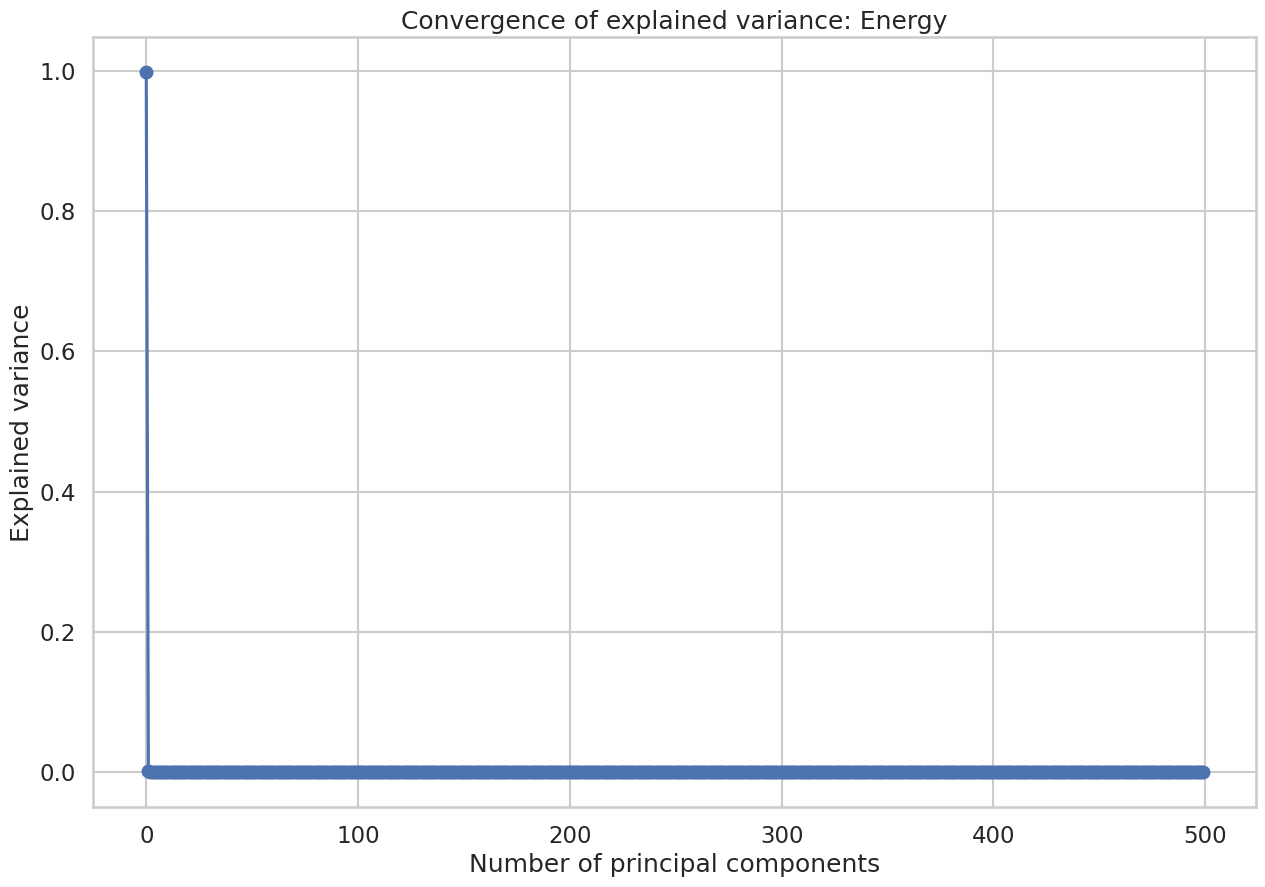

In [81]:
plt.plot(var_fraction_e, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance")
plt.title("Convergence of explained variance: Energy")
plt.savefig("./images/pca_explained_variance_e.png")
plt.show()

### Kernel func

In [ ]:
l_pca = 400
sigma_pca = 10
K = np.array([[kernel_func(x1, x2, sigma_pca, l_pca) 
               for x2 in T_stepOne_total]
               for x1 in T_stepOne_total])

K[np.diag_indices_from(K)] += 0.001


In [ ]:
eigenvals_K, eigenvecs_K = np.linalg.eigh(K)

#print(eigenvals_K)

idx = np.argsort(eigenvals_K)[::-1] #returns the indices that would sort an array

eigenvals_K = eigenvals_K[idx]
eigenvecs_K = eigenvecs_K[:, idx]

In [ ]:
def generate_phi(sigma, l):
    mean_data = np.concatenate([GP_mean_lat_file, GP_mean_extract])
    k = []
    mean = [phifromsc2(el) for el in mean_data]
    for x1 in T_stepOne_total:
        k_row = []
        for x2 in T_stepOne_total:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_stepOne_total))
    sample = mean + np.dot(Sigma, u)

    return sample

In [ ]:
phi_samples = []

for _ in range(N):
    phi_sample = generate_phi(sigma_pca, l_pca)
    phi_samples.append(phi_sample)

phi_samples = np.array(phi_samples)

In [ ]:
phi_samples = np.array(phi_samples)

mean_phi = np.mean(phi_samples, axis=0)

X_phi = phi_samples - mean_phi

coeff_phi = X_phi @ eigenvecs_K

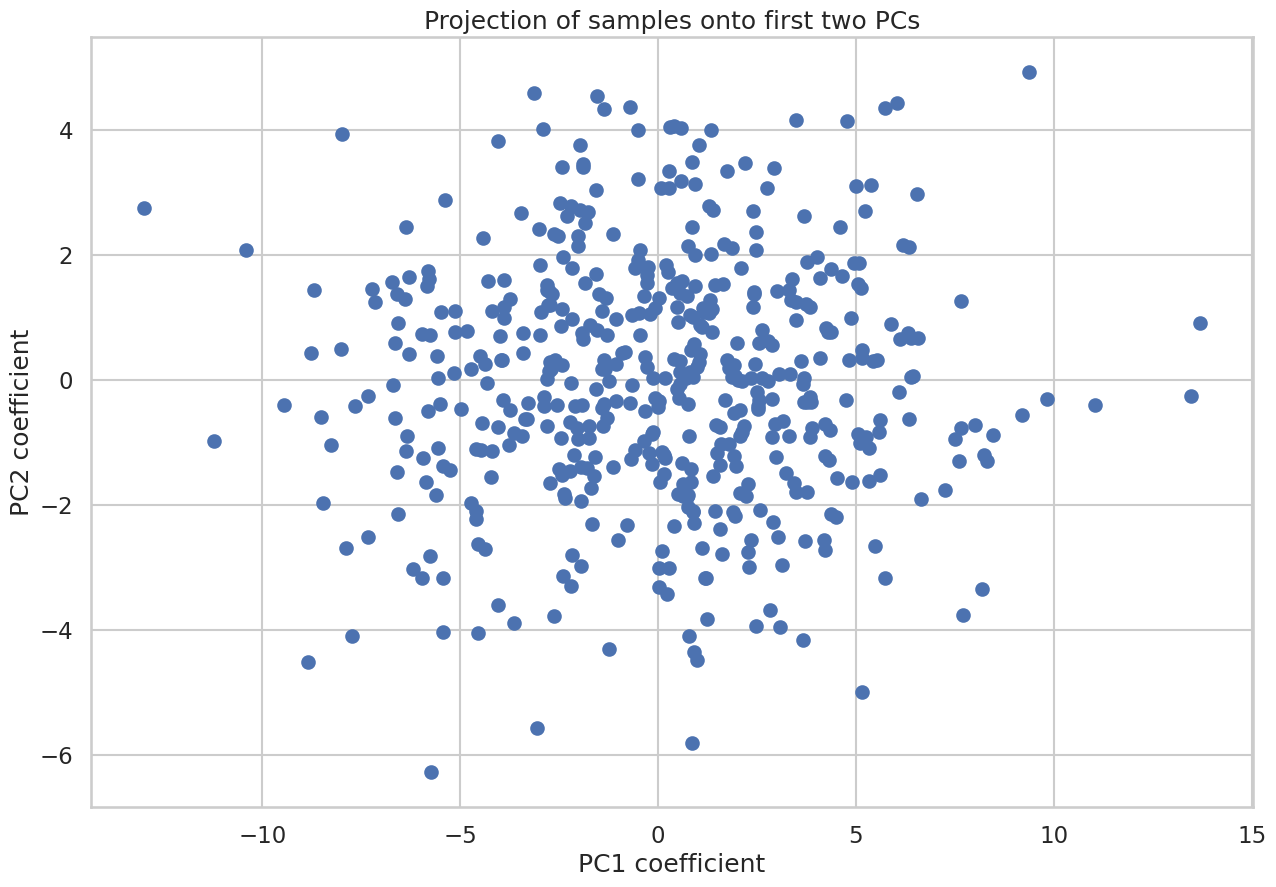

In [ ]:
plt.scatter(coeff_phi[:,0], coeff_phi[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs")
plt.savefig("./images/pca_projection_phi.png")
plt.show()

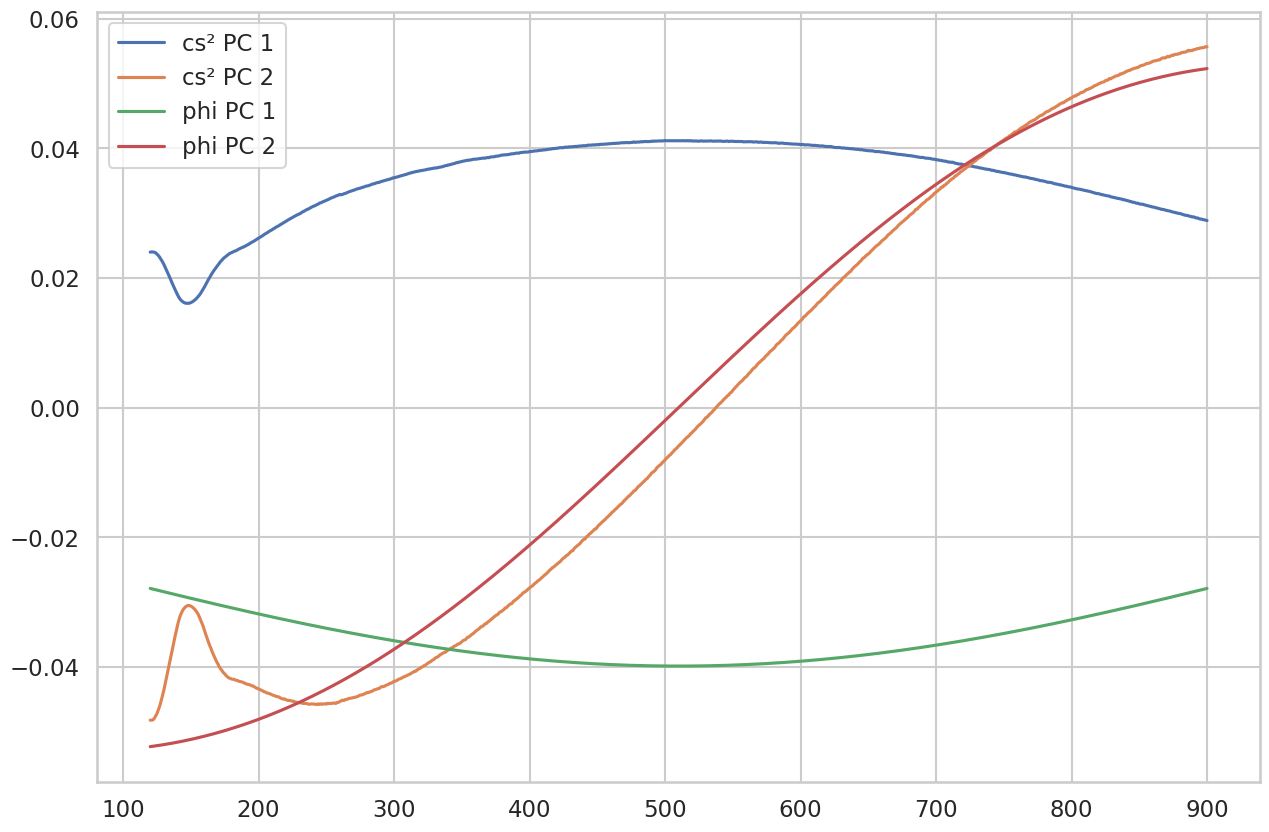

In [ ]:
plt.plot(T_stepOne_total, PCs[0], label="cs² PC 1")
plt.plot(T_stepOne_total, PCs[1], label="cs² PC 2")
plt.plot(T_stepOne_total, eigenvecs_K[:,0], label="phi PC 1")
plt.plot(T_stepOne_total, eigenvecs_K[:,1], label="phi PC 2")
plt.legend()
plt.savefig("./images/pca_kernel_mode_comparison.png")
plt.show()

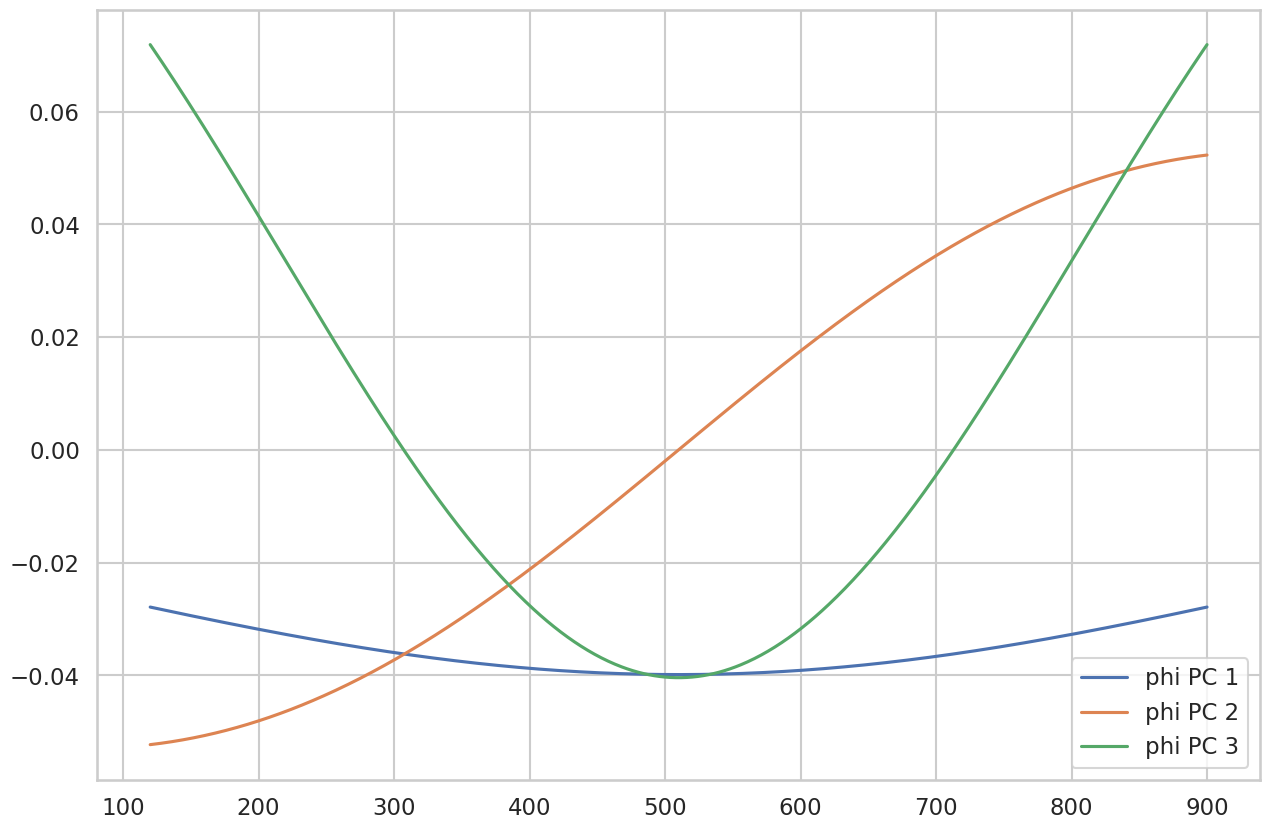

In [ ]:

plt.plot(T_stepOne_total, eigenvecs_K[:,0], label="phi PC 1")
plt.plot(T_stepOne_total, eigenvecs_K[:,1], label="phi PC 2")
plt.plot(T_stepOne_total, eigenvecs_K[:,2], label="phi PC 3")  
plt.legend()
plt.savefig("./images/kernel_modes.png")
plt.show()

Max abs diff: 4.440892098500626e-16
All close: True


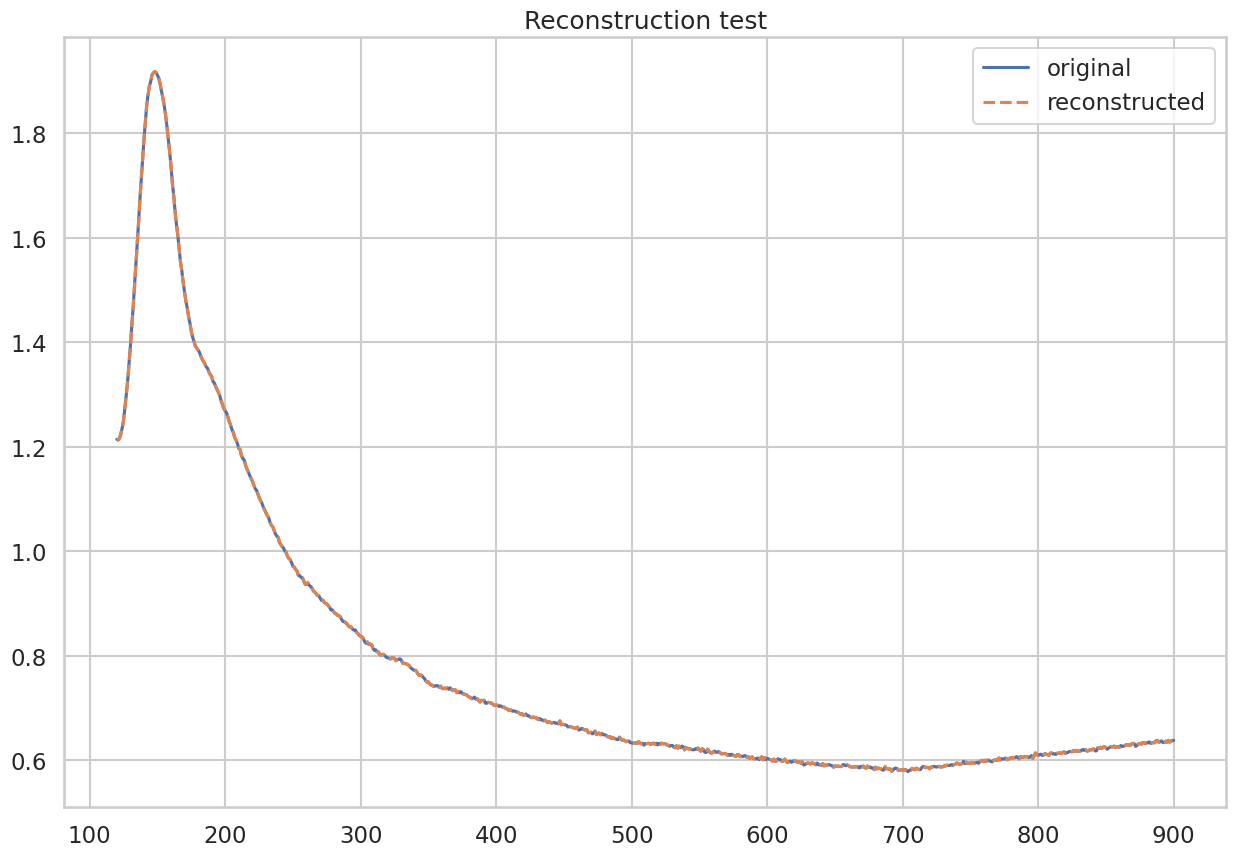

In [ ]:
reconstructed = mean_phi + coeff_phi[0] @ eigenvecs_K.T

original = phi_samples[0]

print("Max abs diff:", np.max(np.abs(reconstructed - original)))
print("All close:", np.allclose(reconstructed, original))

plt.plot(T_stepOne_total, original, label="original")
plt.plot(T_stepOne_total, reconstructed, "--", label="reconstructed")

plt.legend()
plt.title("Reconstruction test")
plt.show()

In [ ]:
var_fraction_K = eigenvals_K / np.sum(eigenvals_K)

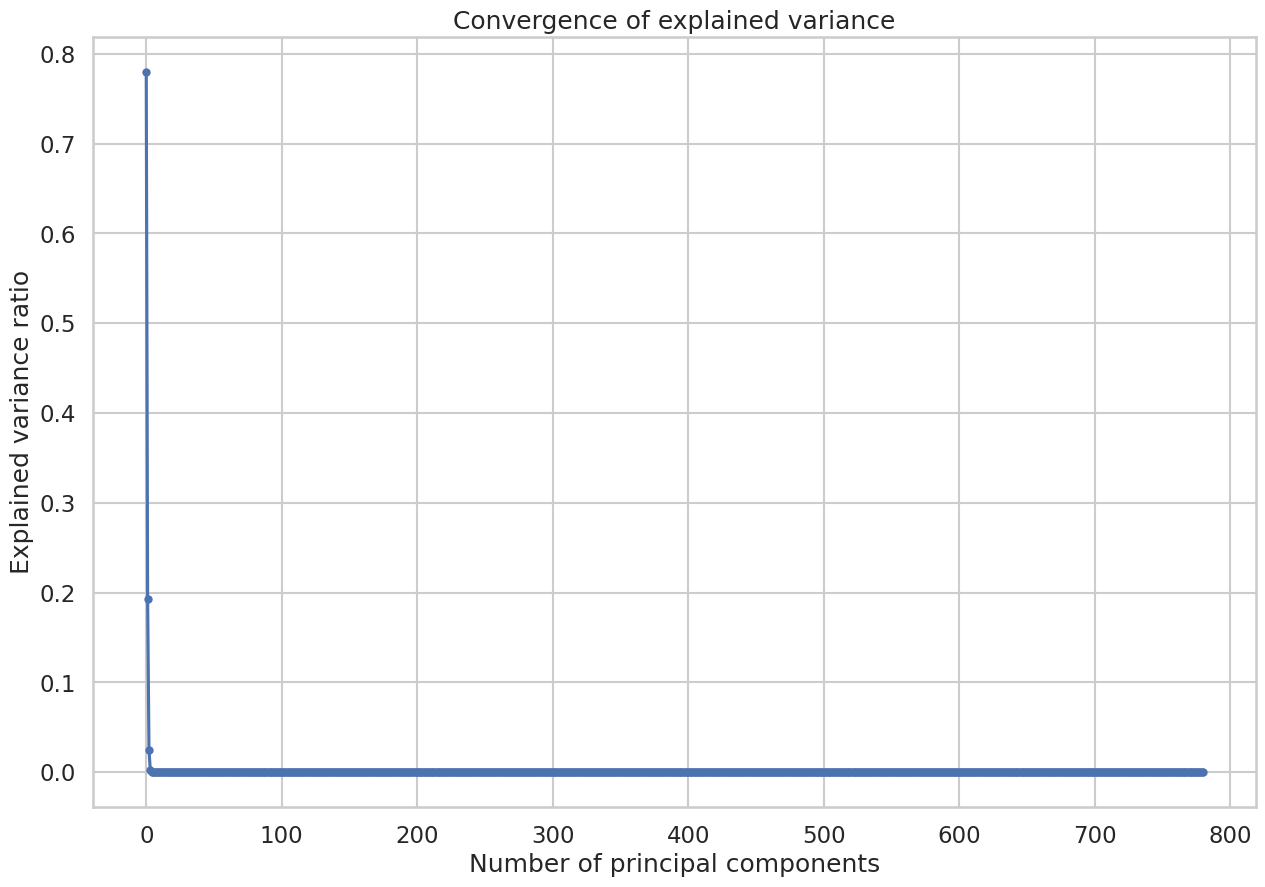

In [ ]:
plt.plot(var_fraction_K, marker='o', markersize=5)
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance ratio")
plt.title("Convergence of explained variance")
plt.savefig(f"./images/pca_explained_variance_phi_l{l_pca}_sigma{sigma_pca}.png")
plt.show()

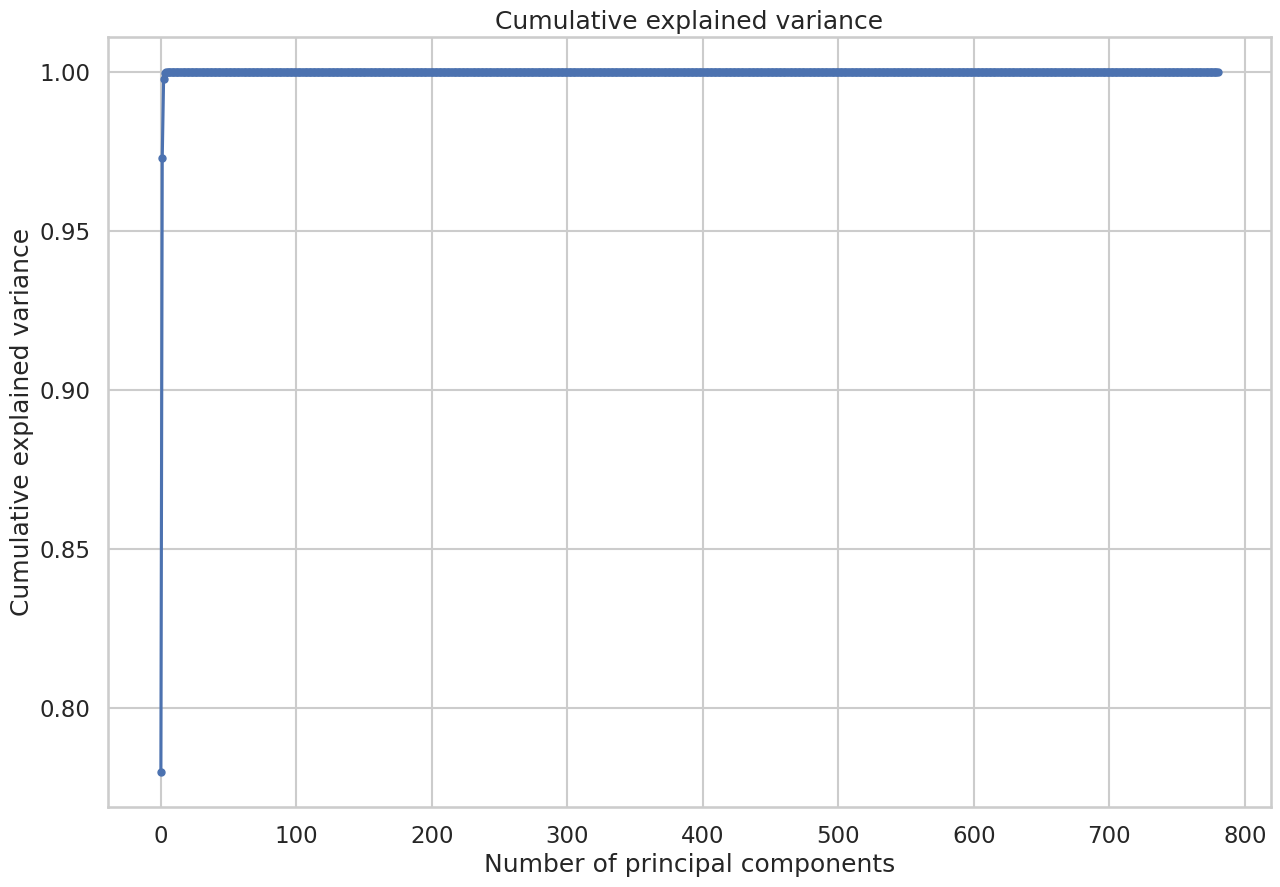

In [ ]:
cum_var_frac = np.cumsum(var_fraction_K)
plt.plot(cum_var_frac, marker='o', markersize=5)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")
plt.savefig(f"./images/pca_cumulative_variance_phi_l{l_pca}_sigma{sigma_pca}.png")
plt.show()